# Doses de vacina: 1ª dose, 2ª dose, reforço e dose única

Este notebook explora a base `vacinas_analitico.csv` para ajudar o cidadão a **entender o que significam os tipos de dose registrados** (1ª dose, 2ª dose, reforço, dose única etc.) — sem transformar isso em acompanhamento de pessoa nenhuma.

## ⚠️ Aviso sobre os dados

- **A base não identifica pacientes.** O campo de identificação do paciente foi omitido/anonimizado na origem (G-MUS). Isso significa que **não é possível seguir o histórico de uma mesma pessoa** ao longo do tempo, nem saber se ela "completou o esquema vacinal", "abandonou" ou está "protegida".
- Cada linha é um **registro de aplicação** (um evento), não uma pessoa. A mesma pessoa pode gerar várias linhas (por exemplo, 1ª dose e depois 2ª dose), mas **não temos como ligar essas linhas entre si**.
- **Duplicidades exatas foram mantidas de propósito.** O relatório nativo do G-MUS pode gerar entradas idênticas para imunizantes aplicados no mesmo lote/período quando o identificador do paciente é retirado. Essas duplicidades foram preservadas para manter o volume real de procedimentos registrados na fonte — ou seja, **este notebook conta registros/procedimentos, não pessoas**.
- As datas de aplicação podem vir em formato completo (`DD/MM/AAAA`) ou agrupadas por mês/ano (`MM/AAAA`), refletindo a digitação de carteirinhas físicas antigas. O código abaixo trata os dois formatos.
- A base não tem uma coluna de "sala" separada. A divisão organizacional disponível é o **bairro da unidade que aplicou a dose** (`nome_do_bairro`). Usamos essa coluna ao longo do notebook como o nível de "local de atendimento" mencionado nas perguntas orientadoras — ela agrupa unidades/postos, não pessoas.
- Existem alguns registros (poucos) com o campo de dose ausente, por divergência de preenchimento na origem. Eles são mostrados, não descartados.

**O que este notebook NÃO faz:** não calcula cobertura vacinal, não afirma abandono de esquema, não diz se uma pessoa está "vacinada" ou "protegida". Ele descreve **como os tipos de dose se distribuem** entre vacinas, bairros, estratégias e períodos — é uma leitura operacional da base, não uma leitura epidemiológica individual.


## Sumário
1. Preparação do ambiente
2. Visão geral da base
3. Padronizando o texto de dose (sem perder o original)
4. Tratando as datas de aplicação
5. **Pergunta 1** — Quais tipos de dose mais aparecem na base?
6. **Pergunta 2** — A composição de doses muda entre vacinas, bairros e períodos?
7. **Pergunta 3** — Há vacinas com muita 1ª dose e pouca 2ª dose (ou o inverso)?
8. **Pergunta 4** — Quais registros incompletos ou fora do padrão merecem atenção?
9. Exploração interativa (filtros por vacina, bairro, estratégia e ano)
10. Resumo para o cidadão

### 📖 Guia rápido para ler os gráficos (não precisa de conhecimento prévio)

- **Registro** = uma linha da base = uma aplicação de vacina registrada. **Não é uma pessoa.**
- **n** = número de registros. Aparece ao lado do nome em vários gráficos para você saber o "tamanho" de cada grupo (um grupo com `n = 5` diz muito menos do que um com `n = 22.646`).
- **Quantidade × porcentagem:** *quantidade* mostra o volume (quantos registros); *porcentagem* mostra a composição (como o grupo se divide), independentemente do tamanho.
- **Cores fixas:** cada tipo de dose tem **sempre a mesma cor** em todos os gráficos (por exemplo, marrom = dose única, azul = 1ª dose).
- **Asterisco (\*)** = nome abreviado ou rótulo suspeito; a explicação aparece ao lado do gráfico ou logo abaixo dele.
- **Números no padrão brasileiro:** `17.021` = dezessete mil e vinte e um; `0,85` = oitenta e cinco centésimos.
- Abaixo de cada gráfico há uma caixa **"Como ler"** com a explicação em linguagem simples.

## 1. Preparação do ambiente

Se estiver rodando no **Google Colab**, faça upload do arquivo `vacinas_analitico.csv` quando solicitado (ou ajuste o caminho abaixo, se já subiu o arquivo para o Drive).

In [ ]:
# Google Colab já traz pandas, matplotlib e ipywidgets instalados.
# Só instalamos o ipywidgets se estiver faltando (SEM --upgrade: atualizar a versão
# no Colab pode quebrar os filtros interativos da seção 9).
import importlib.util, subprocess, sys

if importlib.util.find_spec("ipywidgets") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ipywidgets"])
print("Ambiente pronto.")

Ambiente pronto.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors
import re
import os
import textwrap

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 90)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.family'] = 'DejaVu Sans'   # fonte padrão do Colab (tem ª, º, ≥, ÷)

In [ ]:
CSV_PATH = "vacinas_analitico.csv"

if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print("Arquivo não encontrado localmente. Faça upload do CSV:")
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"Não encontrei '{CSV_PATH}'. Coloque o arquivo na mesma pasta do notebook "
            "ou rode isso no Google Colab para poder fazer upload."
        )

try:
    df = pd.read_csv(CSV_PATH)
except UnicodeDecodeError:
    df = pd.read_csv(CSV_PATH, encoding="latin-1")
print(f"Registros: {len(df):,} | Colunas: {list(df.columns)}")
df.head()


Arquivo não encontrado localmente. Faça upload do CSV:


Saving vacinas_analitico.csv to vacinas_analitico.csv
Registros: 30,883 | Colunas: ['nome_do_bairro', 'nome_da_vacina', 'codigo_da_vacina', 'estrategia', 'codigo_da_estrategia', 'dose', 'codigo_da_dose', 'vacina_estrategia_e_dose', 'lote', 'validade_do_lote', 'data_da_aplicacao', 'origem']


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação


## 2. Visão geral da base

Antes de falar de doses, um retrato rápido: quantos registros, quantos valores nulos, quantas vacinas, bairros e estratégias distintas existem.

In [ ]:
print("Dimensão:", df.shape)
print()
print("Valores ausentes por coluna:")
print(df.isnull().sum())


Dimensão: (30883, 12)

Valores ausentes por coluna:
nome_do_bairro                0
nome_da_vacina                0
codigo_da_vacina              0
estrategia                    0
codigo_da_estrategia          0
dose                          9
codigo_da_dose                9
vacina_estrategia_e_dose      0
lote                          0
validade_do_lote              0
data_da_aplicacao           860
origem                      860
dtype: int64


In [ ]:
resumo = pd.DataFrame({
    "valores distintos": [
        df['nome_da_vacina'].nunique(),
        df['nome_do_bairro'].nunique(),
        df['estrategia'].nunique(),
        df['dose'].nunique(),
        df['origem'].nunique(),
    ]
}, index=["vacinas", "bairros (unidades/salas)", "estratégias", "textos de dose distintos", "origem do registro"])
resumo


,valores distintos
vacinas,41
bairros (unidades/salas),15
estratégias,12
textos de dose distintos,27
origem do registro,3


## 3. Padronizando o texto de dose (sem perder o original)

O campo `dose` vem em texto livre, com muitas variações (`1ª DOSE`, `ÚNICA`, `REFORÇO`, `2º REFORÇO`, `1ª DOSE DOBRADA`, `exposição - 3ª DOSE`, `DOSE ZERO`, `REVACINAÇÃO`, etc.). Para poder comparar, criamos colunas **novas** derivadas por regras (expressões regulares), mas **a coluna original `dose` é mantida intacta** — nada é sobrescrito ou perdido.

Novas colunas criadas:
- `dose_categoria`: agrupamento legível (1ª DOSE, 2ª DOSE, 3ª DOSE+, REFORÇO, DOSE ÚNICA, DOSE ZERO, REVACINAÇÃO, PROFILAXIA/TRATAMENTO, DOSE SEM ESPECIFICAÇÃO, NÃO INFORMADA)
- `dose_numero`: o número da dose/reforço quando existe (1, 2, 3, 4...)
- `dose_dobrada`: `True` quando o texto indica dose dobrada
- `dose_pos_exposicao`: `True` quando o texto indica contexto de pós-exposição

In [ ]:
def parse_dose(texto):
    if pd.isnull(texto):
        return pd.Series({
            "dose_categoria": "NÃO INFORMADA",
            "dose_numero": np.nan,
            "dose_dobrada": False,
            "dose_pos_exposicao": False,
        })
    t = str(texto).upper()
    dobrada = "DOBRADA" in t
    exposicao = "EXPOSIÇÃO" in t or "EXPOSICAO" in t

    num_match = re.search(r"(\d+)[ºªA]?\s*(DOSE|REFORÇO|REFORCO)", t)
    numero = int(num_match.group(1)) if num_match else None

    if "ÚNICA" in t or "UNICA" in t:
        cat = "DOSE ÚNICA"
    elif "ZERO" in t:
        cat = "DOSE ZERO"
    elif "REVACINAÇÃO" in t or "REVACINACAO" in t:
        cat = "REVACINAÇÃO"
    elif "REFORÇO" in t or "REFORCO" in t:
        cat = "REFORÇO"
    elif "PROFILAXIA" in t or "TRATAMENTO" in t:
        cat = "PROFILAXIA/TRATAMENTO"
    elif numero == 1:
        cat = "1ª DOSE"
    elif numero == 2:
        cat = "2ª DOSE"
    elif numero and numero >= 3:
        cat = "3ª DOSE OU MAIS"
    elif t.strip() == "DOSE":
        cat = "DOSE (SEM ESPECIFICAÇÃO)"
    else:
        cat = "OUTRO/NÃO PADRONIZADO"

    return pd.Series({
        "dose_categoria": cat,
        "dose_numero": numero,
        "dose_dobrada": dobrada,
        "dose_pos_exposicao": exposicao,
    })

dose_info = df["dose"].apply(parse_dose)
df = pd.concat([df, dose_info], axis=1)
# garante os tipos corretos das colunas novas (a coluna original "dose" não é tocada)
df["dose_dobrada"] = df["dose_dobrada"].astype(bool)
df["dose_pos_exposicao"] = df["dose_pos_exposicao"].astype(bool)
df["dose_numero"] = pd.to_numeric(df["dose_numero"], errors="coerce")

print("Checagem: nenhuma linha perdeu o texto original de dose ->",
      df["dose"].isnull().sum() == df["dose_categoria"].eq("NÃO INFORMADA").sum())

df[["dose", "dose_categoria", "dose_numero", "dose_dobrada", "dose_pos_exposicao"]].sample(8, random_state=1)


Checagem: nenhuma linha perdeu o texto original de dose -> True


,dose,dose_categoria,dose_numero,dose_dobrada,dose_pos_exposicao
482,ÚNICA,DOSE ÚNICA,NaN,False,False
6945,ÚNICA,DOSE ÚNICA,NaN,False,False
95,ÚNICA,DOSE ÚNICA,NaN,False,False
29793,ÚNICA,DOSE ÚNICA,NaN,False,False
17617,DOSE,DOSE (SEM ESPECIFICAÇÃO),NaN,False,False
19415,ÚNICA,DOSE ÚNICA,NaN,False,False
8723,ÚNICA,DOSE ÚNICA,NaN,False,False
18329,ÚNICA,DOSE ÚNICA,NaN,False,False


In [ ]:
# Quantos registros caíram em cada categoria padronizada, e quais textos originais formam cada uma
tabela_categorias = (
    df.groupby("dose_categoria")["dose"]
    .agg(registros="count", exemplos_de_texto_original=lambda s: sorted(s.dropna().unique())[:5])
    .sort_values("registros", ascending=False)
)
tabela_categorias


,registros,exemplos_de_texto_original
dose_categoria,,
DOSE ÚNICA,17021,[ÚNICA]
1ª DOSE,4882,"[1ª DOSE, 1ª DOSE DOBRADA]"
2ª DOSE,3199,"[2ª DOSE, 2ª DOSE DOBRADA, exposição - 2ª DOSE]"
REFORÇO,2732,"[1º REFORÇO, 2º REFORÇO, REFORÇO]"
3ª DOSE OU MAIS,1356,"[3ª DOSE, 3ª DOSE DOBRADA, 4ª DOSE, 4ª DOSE DOBRADA, exposição - 3ª DOSE]"
DOSE (SEM ESPECIFICAÇÃO),1244,[DOSE]
REVACINAÇÃO,235,"[1ª DOSE REVACINAÇÃO, 2ª DOSE REVACINAÇÃO, 2ª DOSE REVACINAÇÃO DOBRADA, 3ª DOSE REVACI..."
PROFILAXIA/TRATAMENTO,104,"[PROFILAXIA/TRATAMENTO COM 1 FRASCO-AMPOLA/AMPOLA, PROFILAXIA/TRATAMENTO COM 2 FRASCOS..."
DOSE ZERO,101,[DOSE ZERO]


### Paleta de cores fixa por categoria de dose

Para que a **mesma cor sempre represente a mesma categoria** em todos os gráficos deste notebook — o que é essencial para comparar vacina com vacina, bairro com bairro, estratégia com estratégia e ano com ano — definimos abaixo uma paleta fixa e duas funções auxiliares, usadas em todos os gráficos de composição de dose a partir daqui.

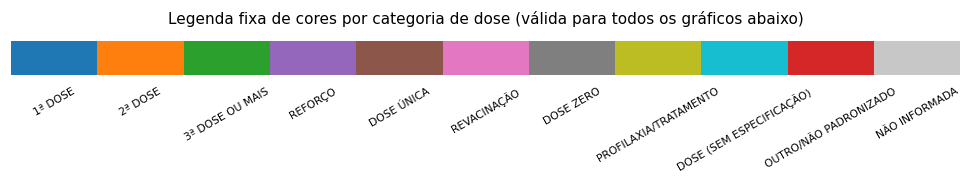

In [ ]:
CATEGORY_ORDER = [
    "1ª DOSE",
    "2ª DOSE",
    "3ª DOSE OU MAIS",
    "REFORÇO",
    "DOSE ÚNICA",
    "REVACINAÇÃO",
    "DOSE ZERO",
    "PROFILAXIA/TRATAMENTO",
    "DOSE (SEM ESPECIFICAÇÃO)",
    "OUTRO/NÃO PADRONIZADO",
    "NÃO INFORMADA",
]

CATEGORY_COLORS = {
    "1ª DOSE": "#1f77b4",
    "2ª DOSE": "#ff7f0e",
    "3ª DOSE OU MAIS": "#2ca02c",
    "REFORÇO": "#9467bd",
    "DOSE ÚNICA": "#8c564b",
    "REVACINAÇÃO": "#e377c2",
    "DOSE ZERO": "#7f7f7f",
    "PROFILAXIA/TRATAMENTO": "#bcbd22",
    "DOSE (SEM ESPECIFICAÇÃO)": "#17becf",
    "OUTRO/NÃO PADRONIZADO": "#d62728",
    "NÃO INFORMADA": "#c7c7c7",
}

def ordenar_categorias(tabela):
    """Reordena as colunas de uma tabela (vacina x categoria, bairro x categoria etc.)
    sempre na mesma ordem de categorias, para friso visual consistente entre gráficos."""
    ordem_presente = [c for c in CATEGORY_ORDER if c in tabela.columns]
    extras = [c for c in tabela.columns if c not in CATEGORY_ORDER]
    return tabela[ordem_presente + extras]

def cores_para(colunas):
    """Devolve a lista de cores fixas correspondente a uma lista/índice de categorias."""
    return [CATEGORY_COLORS.get(c, "#999999") for c in colunas]

# Legenda visual única de referência: a partir daqui, toda categoria aparece sempre com a mesma cor
fig, ax = plt.subplots(figsize=(9, 1.6))
for i, cat in enumerate(CATEGORY_ORDER):
    ax.barh(0, 1, left=i, color=CATEGORY_COLORS[cat])
    ax.text(i + 0.5, -0.65, cat, ha="center", va="top", fontsize=7, rotation=30)
ax.set_xlim(0, len(CATEGORY_ORDER))
ax.set_ylim(-1.3, 0.6)
ax.axis("off")
ax.set_title("Legenda fixa de cores por categoria de dose (válida para todos os gráficos abaixo)", fontsize=10)
plt.tight_layout()
plt.show()


### Funções auxiliares de formatação dos gráficos

As funções abaixo servem **apenas para deixar os gráficos mais legíveis** (números no padrão brasileiro, folga à direita para os valores não "estourarem", nomes abreviados com legenda etc.). Elas **não alteram nenhum dado** do CSV nem as colunas do `DataFrame`.

In [ ]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ---------- números no padrão brasileiro ----------
def fmt_int(n):
    """17021 -> '17.021'"""
    return f"{int(round(n)):,}".replace(",", ".")

def fmt_dec(x, casas=2):
    """0.5 -> '0,50'"""
    return f"{x:.{casas}f}".replace(".", ",")

def fmt_pct(p, casas=1):
    """0.551 -> '55,1%'  (p entre 0 e 1). Valores minúsculos ganham 2 casas (0,03%)."""
    if casas == 1 and 0 < p < 0.001:
        casas = 2
    return f"{p * 100:.{casas}f}".replace(".", ",") + "%"

def eixo_milhar(ax, eixo="x"):
    f = mticker.FuncFormatter(lambda v, _: fmt_int(v))
    (ax.xaxis if eixo == "x" else ax.yaxis).set_major_formatter(f)

# ---------- visual limpo + folga à direita (evita número "estourando" a borda) ----------
def estilo_barras(ax, valor_max, folga=0.18):
    ax.set_xlim(0, valor_max * (1 + folga))
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.set_ylabel("")

def cor_texto_para(cor_hex):
    """Texto preto em fundo claro, branco em fundo escuro."""
    r, g, b = mcolors.to_rgb(cor_hex)
    return "black" if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else "white"

# ---------- meses em português ----------
MESES_ABREV = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

def rotulo_mes(periodo):
    """'2026-03' -> 'mar/2026'"""
    ano, mes = str(periodo).split("-")
    return f"{MESES_ABREV[int(mes) - 1]}/{ano}"

# ---------- nomes curtos de vacina (o nome completo continua na coluna original) ----------
NOMES_CURTOS_VACINA = {
    "Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de 5 anos": "COVID-19 Pfizer infantil (<5 anos)",
    "Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de": "COVID-19 Pfizer infantil (nome cortado)",
    "Vacina COVID-19-RNAm, Pfizer (Comirnaty)": "COVID-19 Pfizer (Comirnaty)",
    "Vacina polio injetável (inativada poliomielite)": "Poliomielite injetável (VIP)",
    "Vacina polio injetável": "Poliomielite injetável (nome cortado)",
    "Vacina penta (DTP/HepB/Hib)": "Penta (DTP/HepB/Hib)",
    "Vacina penta": "Penta (nome cortado)",
    "Vacina hexa (DTPa/HepB/VIP/Hib)": "Hexa (DTPa/HepB/VIP/Hib)",
    "Vacina difteria e tétano adulto": "Difteria e tétano (adulto)",
    "Vacina sarampo, caxumba, rubéola": "Sarampo/caxumba/rubéola",
    "Vacina sarampo, caxumba, rubéola e varicela": "Sarampo/caxumba/rubéola + varicela",
    "Vacina raiva em cultivo celular vero": "Raiva (cultivo celular vero)",
    "Vacina influenza trivalente": "Influenza (gripe) trivalente",
    "Vacina pneumo 10": "Pneumocócica 10",
    "Vacina pneumo 13": "Pneumocócica 13",
    "Vacina pneumo 23": "Pneumocócica 23",
    "Vacina Pneumo 20": "Pneumocócica 20",
    "Vacina meningo ACWY": "Meningocócica ACWY",
    "Vacina meningo C": "Meningocócica C",
    "Vacina dengue (atenuada)": "Dengue (atenuada)",
    "Vacina dengue": "Dengue (nome cortado)",
    "Vacina hepatite A adulto": "Hepatite A (adulto)",
    "Vacina hepatite A infantil": "Hepatite A (infantil)",
    "Vacina Vírus Sincicial A e B (recombinante)": "Vírus sincicial A e B (recomb.)",
    "Vacina Vírus Sincicial A e B": "Vírus sincicial A e B (nome cortado)",
    "Vacina vírus sincicial respiratório (recombinante, adjuvada)": "Vírus sincicial resp. (adjuvada)",
    "Vacina COVID": "COVID (nome cortado)",
}

def nome_curto_vacina(nome, limite=36):
    if nome in NOMES_CURTOS_VACINA:
        return NOMES_CURTOS_VACINA[nome]
    s = re.sub(r"^Vacina\s+", "", str(nome))
    s = s[:1].upper() + s[1:]
    return s if len(s) <= limite else s[:limite - 1].rstrip() + "…"

def glossario_vacinas(nomes):
    """Tabela 'nome no gráfico -> nome completo na base' (só das que foram encurtadas)."""
    linhas = []
    for n in nomes:
        curto = nome_curto_vacina(n)
        if curto.lower() != re.sub(r"^Vacina\s+", "", str(n)).lower():
            linhas.append({"Nome no gráfico": curto, "Nome completo na base": n})
    return pd.DataFrame(linhas)

# ---------- rótulos de estratégia que confundem o leitor ----------
ESTRATEGIAS_SUSPEITAS = ["19", "Pós", "Rotina (1)"]
ROTULO_ESTRATEGIA = {
    "19": "“19” (= COVID-19)*",
    "Pós": "“Pós” (= Pós-exposição)*",
    "Rotina (1)": "“Rotina (1)”*",
}

# ---------- cores por origem do registro ----------
ORIGEM_CORES = {"Carteirinha": "#4C78A8", "Prontuário": "#F58518", "Tela de Aplicação": "#54A24B"}

# ---------- gráfico de composição (barras 100%) reaproveitado nas seções 6.1, 6.2 e 6.3 ----------
def grafico_composicao(tab_prop, tab_n, titulo, xlabel, rotulos=None, nota=None,
                       figsize=(12.5, 6.2), min_rotulo=0.06):
    """Barras empilhadas 100%: como os tipos de dose se dividem dentro de cada grupo.
    tab_prop: proporções (linhas = grupos, colunas = categorias de dose)
    tab_n:    nº de registros de cada grupo (aparece como 'n =' ao lado do nome)."""
    tab_prop = ordenar_categorias(tab_prop)
    rotulos = rotulos or {}
    nomes = [f"{rotulos.get(g, g)}  (n = {fmt_int(tab_n[g])})" for g in tab_prop.index]
    y = np.arange(len(tab_prop))

    fig, ax = plt.subplots(figsize=figsize)
    esquerda = np.zeros(len(tab_prop))
    handles = []
    for cat in tab_prop.columns:
        vals = tab_prop[cat].values.astype(float)
        if vals.sum() == 0:
            continue
        cor = CATEGORY_COLORS.get(cat, "#999999")
        ax.barh(y, vals, left=esquerda, color=cor, edgecolor="white", linewidth=0.6, height=0.72)
        for yi, (v, l) in enumerate(zip(vals, esquerda)):
            if v >= min_rotulo:
                ax.text(l + v / 2, yi, f"{v * 100:.0f}%", ha="center", va="center",
                        fontsize=8, color=cor_texto_para(cor))
        esquerda += vals
        handles.append(Patch(color=cor, label=cat))

    ax.set_yticks(y)
    ax.set_yticklabels(nomes, fontsize=10)
    ax.invert_yaxis()                                  # maior grupo no topo
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.set_xlabel(xlabel)
    ax.set_title(titulo, loc="left", fontsize=13, fontweight="bold")
    ax.legend(handles=handles, title="Categoria de dose", bbox_to_anchor=(1.025, 1.0),
              loc="upper left", fontsize=9, title_fontsize=9.5, frameon=False)
    if nota:
        y_nota = 1.0 - 0.052 * (len(handles) + 1.8)
        ax.text(1.025, y_nota, textwrap.fill(nota, 40) if "\n" not in nota else nota,
                transform=ax.transAxes, fontsize=8.5, va="top", color="#333333")
    plt.tight_layout()
    plt.show()

print("Funções de formatação carregadas.")

Funções de formatação carregadas.


## 4. Tratando as datas de aplicação (`DD/MM/AAAA` ou `MM/AAAA`)

Criamos `ano_aplicacao` e `ano_mes_aplicacao` (período `AAAA-MM`) que funcionam para os dois formatos. Quando o dia não existe (registro só com mês/ano), ele simplesmente não é usado — só o ano e o mês.

In [ ]:
def extrai_periodo(data_txt):
    if pd.isnull(data_txt):
        return pd.Series({"ano_aplicacao": np.nan, "ano_mes_aplicacao": np.nan})
    s = str(data_txt).strip()
    m_completo = re.match(r"^(\d{2})/(\d{2})/(\d{4})$", s)
    m_mes_ano = re.match(r"^(\d{2})/(\d{4})$", s)
    if m_completo:
        _, mes, ano = m_completo.groups()
    elif m_mes_ano:
        mes, ano = m_mes_ano.groups()
    else:
        return pd.Series({"ano_aplicacao": np.nan, "ano_mes_aplicacao": np.nan})
    return pd.Series({"ano_aplicacao": int(ano), "ano_mes_aplicacao": f"{ano}-{mes}"})

periodo_info = df["data_da_aplicacao"].apply(extrai_periodo)
df = pd.concat([df, periodo_info], axis=1)
df["ano_aplicacao"] = pd.to_numeric(df["ano_aplicacao"], errors="coerce")

print("Registros sem data interpretável:", df["ano_mes_aplicacao"].isnull().sum())
df[["data_da_aplicacao", "ano_aplicacao", "ano_mes_aplicacao"]].dropna().sample(5, random_state=2)


Registros sem data interpretável: 860


,data_da_aplicacao,ano_aplicacao,ano_mes_aplicacao
8733,01/04/2026,2026.0,2026-04
14550,01/06/2026,2026.0,2026-06
8357,01/03/2026,2026.0,2026-03
24423,01/05/2026,2026.0,2026-05
2151,01/04/2026,2026.0,2026-04


## 5. Pergunta 1 — Quais tipos de dose mais aparecem na base?

Dois olhares: o texto **original** de dose (como veio na origem) e a categoria **padronizada** (agrupada pelas regras acima).

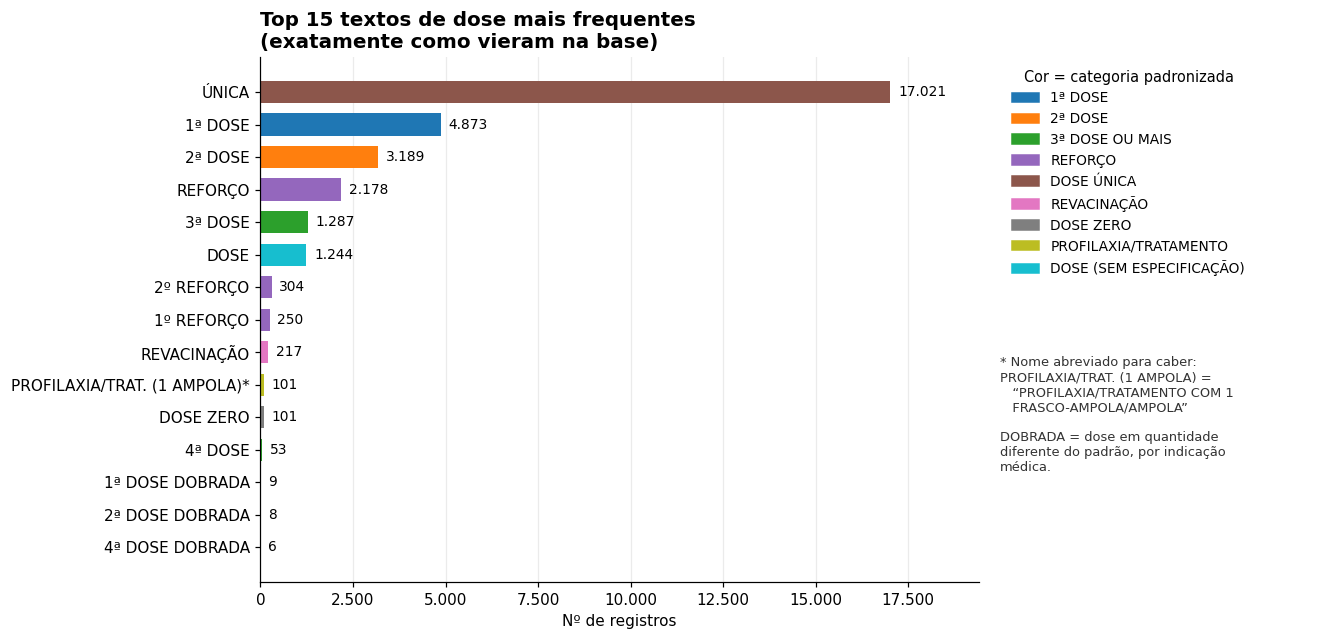

In [ ]:
top_original = df["dose"].value_counts().head(15)
serie = top_original.sort_values()          # o maior fica no topo do gráfico

def rotulo_dose_curto(txt):
    """Encurta só os textos muito longos (o texto original continua intacto na coluna 'dose')."""
    t = str(txt)
    if t.upper().startswith("PROFILAXIA/TRATAMENTO"):
        m = re.search(r"COM (\d+)", t.upper())
        n = m.group(1) if m else "?"
        return f"PROFILAXIA/TRAT. ({n} AMPOLA{'S' if n != '1' else ''})*"
    return t if len(t) <= 26 else t[:25].rstrip() + "…*"

rotulos = [rotulo_dose_curto(t) for t in serie.index]
categorias = [parse_dose(t)["dose_categoria"] for t in serie.index]

fig = plt.figure(figsize=(12.5, 6.2))
gs = fig.add_gridspec(1, 2, width_ratios=[3.3, 1.5], wspace=0.04)
ax = fig.add_subplot(gs[0])
ax_leg = fig.add_subplot(gs[1])
ax_leg.axis("off")

ax.barh(range(len(serie)), serie.values, color=cores_para(categorias), height=0.68)
ax.set_yticks(range(len(serie)))
ax.set_yticklabels(rotulos, fontsize=10)
for i, v in enumerate(serie.values):
    ax.text(v + serie.max() * 0.012, i, fmt_int(v), va="center", fontsize=9)
estilo_barras(ax, serie.max(), folga=0.14)
eixo_milhar(ax)
ax.set_xlabel("Nº de registros")
ax.set_title("Top 15 textos de dose mais frequentes\n(exatamente como vieram na base)",
             loc="left", fontsize=13, fontweight="bold")

# legenda: cores = categoria padronizada + explicação dos nomes abreviados
cats_presentes = [c for c in CATEGORY_ORDER if c in categorias]
ax_leg.legend(handles=[Patch(color=CATEGORY_COLORS[c], label=c) for c in cats_presentes],
              title="Cor = categoria padronizada", loc="upper left", frameon=False,
              fontsize=9, title_fontsize=9.5)
linhas = []
abreviados = [(r, t) for r, t in zip(rotulos, serie.index) if r.endswith("*")]
if abreviados:
    linhas.append("* Nome abreviado para caber:")
    for r, t in abreviados:
        linhas.append(textwrap.fill(f"{r.rstrip('*')} = “{t}”", 36, subsequent_indent="   "))
    linhas.append("")
if any("DOBRADA" in str(t).upper() for t in serie.index):
    linhas.append(textwrap.fill("DOBRADA = dose em quantidade diferente do padrão, por indicação médica.", 36))
y_txt = 0.97 - 0.05 * (len(cats_presentes) + 1.8)
ax_leg.text(0.0, y_txt, "\n".join(linhas), transform=ax_leg.transAxes, va="top", fontsize=8.5, color="#333333")
plt.show()

> **💡 Como ler:** cada barra é um texto de dose **exatamente como está escrito na base**. A **cor** mostra em qual categoria padronizada ele foi agrupado (a mesma cor será usada nos gráficos seguintes). Nomes com **\*** foram abreviados só para caber no gráfico — o texto original completo está na legenda ao lado. O número no fim de cada barra é a quantidade de registros.

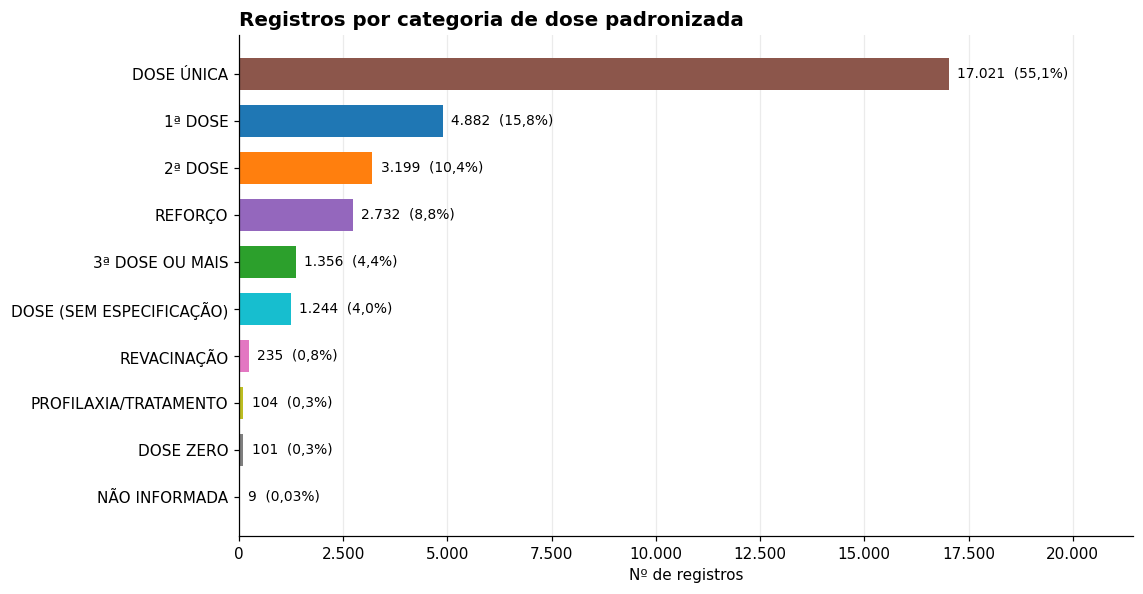

In [ ]:
cat_counts = df["dose_categoria"].value_counts()
serie_cat = cat_counts.sort_values()

fig, ax = plt.subplots(figsize=(10.5, 5.5))
ax.barh(serie_cat.index, serie_cat.values, color=cores_para(serie_cat.index), height=0.68)
for i2, v in enumerate(serie_cat.values):
    ax.text(v + serie_cat.max() * 0.012, i2, f"{fmt_int(v)}  ({fmt_pct(v / len(df))})",
            va="center", fontsize=9)
estilo_barras(ax, serie_cat.max(), folga=0.26)   # folga à direita: o número não estoura mais a borda
eixo_milhar(ax)
ax.set_xlabel("Nº de registros")
ax.set_title("Registros por categoria de dose padronizada", loc="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

> **💡 Como ler:** aqui os textos parecidos foram **agrupados em categorias** (por exemplo, "1º REFORÇO" e "2º REFORÇO" viram "REFORÇO"). Ao lado de cada barra aparecem a quantidade e a **porcentagem do total de registros da base**. Por isso os números daqui são um pouco diferentes do gráfico anterior: ali cada variação de texto aparecia separada.

**Leitura:** a categoria `DOSE ÚNICA` domina a base — isso é esperado, já que muitas vacinas do calendário (febre amarela, HPV em alguns esquemas, algumas campanhas) são registradas assim por padrão de sistema, não porque "poucas pessoas tomaram a 2ª dose". Comparar `DOSE ÚNICA` com `1ª/2ª dose` só faz sentido **dentro da mesma vacina**, que é o que fazemos a seguir.

### ✍️ Resposta da pergunta 1:

O tipo de dose que mais aparece é a **dose única**: **17.021 registros (55,1%** da base). Depois vêm a **1ª dose** (4.882; 15,8%), a **2ª dose** (3.199; 10,4%), o **reforço** (2.732; 8,8%), a **3ª dose ou mais** (1.356; 4,4%) e o texto "DOSE" sem especificação (1.244; 4,0%). Revacinação, profilaxia/tratamento, dose zero e dose não informada ficam, cada uma, abaixo de 1%.

**Por que a dose única domina?** Porque a vacina de gripe (influenza) tem 15.809 registros e quase todos entram como dose única: são 15.097 dos 17.021 registros de dose única (**cerca de 89%**). Sem a gripe, a **1ª dose** passa a ser o tipo mais frequente (29% dos registros), seguida da 2ª dose (20%) e do reforço (18%).

*Lembrete:* são contagens de **registros de aplicação**, não de pessoas.

## 6. Pergunta 2 — A composição de doses muda entre vacinas, bairros (unidades) e períodos?

### 6.1 Por vacina (top 12 mais aplicadas)

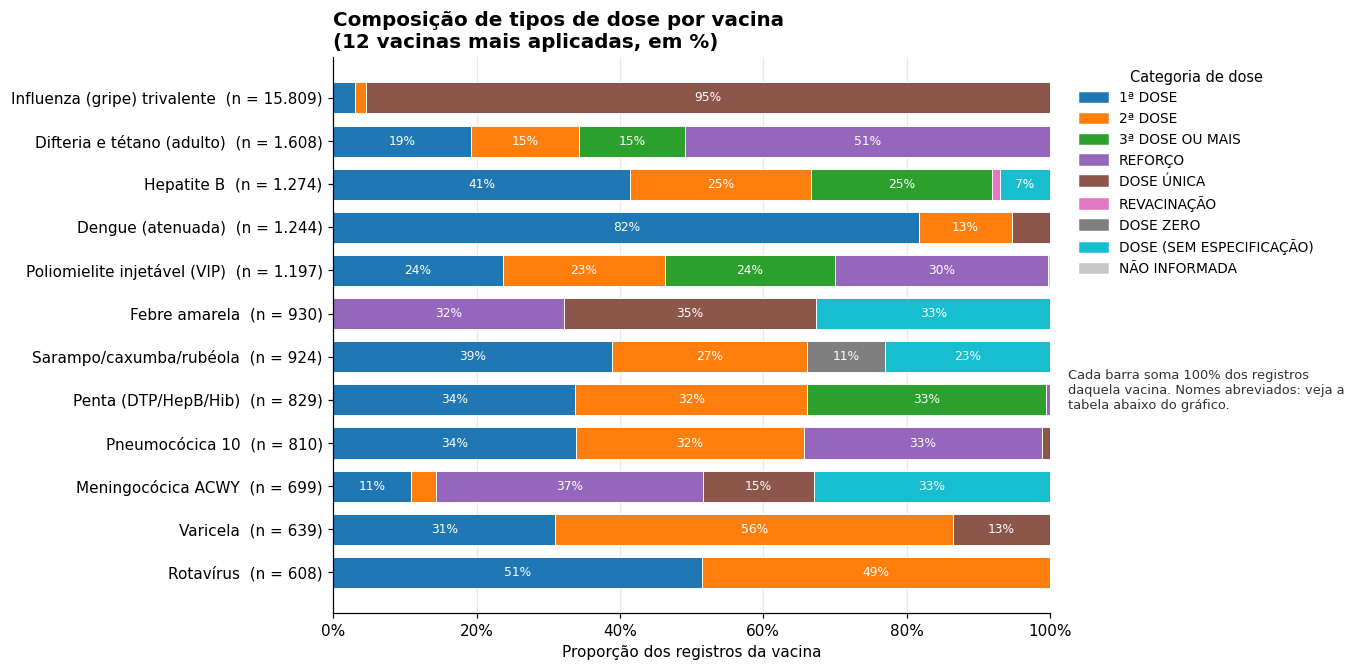

,Nome no gráfico,Nome completo na base
0,Influenza (gripe) trivalente,Vacina influenza trivalente
1,Difteria e tétano (adulto),Vacina difteria e tétano adulto
2,Poliomielite injetável (VIP),Vacina polio injetável (inativada poliomielite)
3,Sarampo/caxumba/rubéola,"Vacina sarampo, caxumba, rubéola"
4,Pneumocócica 10,Vacina pneumo 10
5,Meningocócica ACWY,Vacina meningo ACWY


In [ ]:
top_vacinas = df["nome_da_vacina"].value_counts().head(12).index

tab_vacina_dose = (
    df[df["nome_da_vacina"].isin(top_vacinas)]
    .groupby(["nome_da_vacina", "dose_categoria"])
    .size()n
    .unstack(fill_value=0)
    .loc[top_vacinas]
)
tab_vacina_n = tab_vacina_dose.sum(axis=1)
# proporção dentro de cada vacina, para comparar composição (não volume)
tab_vacina_prop = tab_vacina_dose.div(tab_vacina_n, axis=0)
tab_vacina_prop = ordenar_categorias(tab_vacina_prop)

grafico_composicao(
    tab_vacina_prop, tab_vacina_n,
    titulo="Composição de tipos de dose por vacina\n(12 vacinas mais aplicadas, em %)",
    xlabel="Proporção dos registros da vacina",
    rotulos={v: nome_curto_vacina(v) for v in tab_vacina_prop.index},
    nota="Cada barra soma 100% dos registros daquela vacina. Nomes abreviados: veja a tabela abaixo do gráfico.",
)

g = glossario_vacinas(tab_vacina_prop.index)
g if len(g) else None

> **💡 Como ler:** cada linha é uma vacina e a barra inteira representa **100% dos registros dela**; as cores mostram como esses registros se dividem entre 1ª dose, 2ª dose, reforço etc. Os percentuais dentro da barra aparecem quando o pedaço é ≥ 6%. O **n** ao lado do nome diz quantos registros aquela vacina tem — a gripe (influenza) domina a base, então quase toda ela aparece como dose única.

### 6.2 Por bairro/unidade

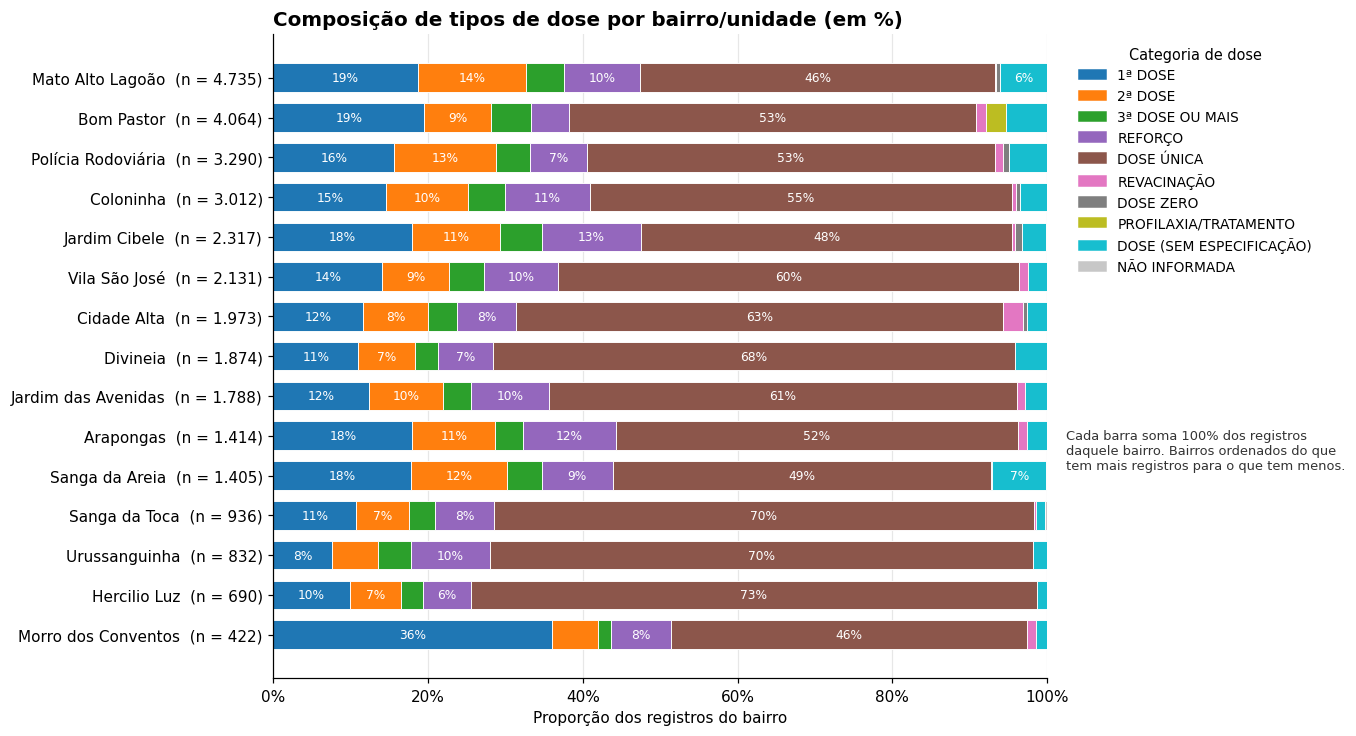

In [ ]:
tab_bairro_dose = (
    df.groupby(["nome_do_bairro", "dose_categoria"])
    .size()
    .unstack(fill_value=0)
)
tab_bairro_n = tab_bairro_dose.sum(axis=1)
tab_bairro_prop = tab_bairro_dose.div(tab_bairro_n, axis=0)
tab_bairro_prop = ordenar_categorias(tab_bairro_prop)
tab_bairro_prop = tab_bairro_prop.loc[tab_bairro_n.sort_values(ascending=False).index]   # maiores unidades no topo

grafico_composicao(
    tab_bairro_prop, tab_bairro_n,
    titulo="Composição de tipos de dose por bairro/unidade (em %)",
    xlabel="Proporção dos registros do bairro",
    nota="Cada barra soma 100% dos registros daquele bairro. Bairros ordenados do que tem mais registros para o que tem menos.",
    figsize=(12.5, 6.8),
)

> **💡 Como ler:** cada linha é o bairro da unidade que aplicou a vacina e a barra inteira é **100% dos registros daquele bairro**. Barras muito parecidas indicam unidades com o mesmo tipo de atendimento; diferenças costumam refletir *o que* cada unidade vacinou no período (mais gripe, mais vacinas de bebê etc.).

### 6.3 Por estratégia de vacinação

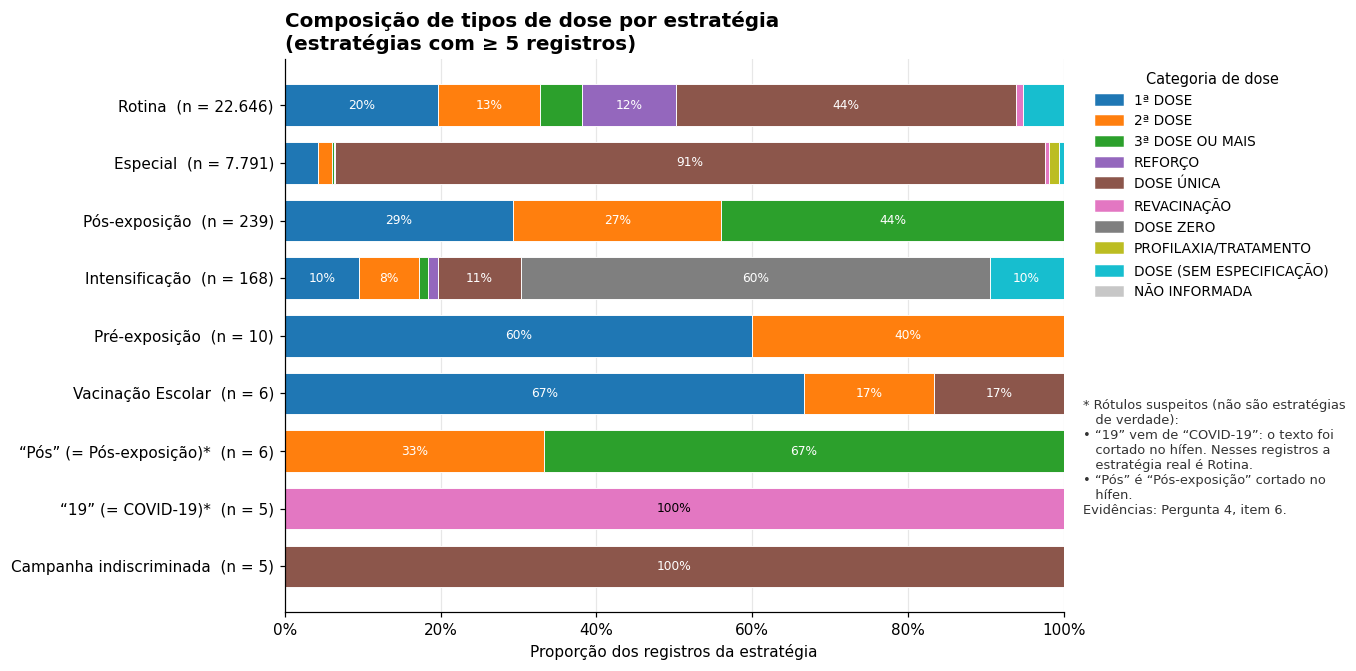

In [ ]:
tab_estrategia_dose = (
    df.groupby(["estrategia", "dose_categoria"])
    .size()
    .unstack(fill_value=0)
)
tab_estrategia_n = tab_estrategia_dose.sum(axis=1)
tab_estrategia_prop = tab_estrategia_dose.div(tab_estrategia_n, axis=0)
tab_estrategia_prop = ordenar_categorias(tab_estrategia_prop)

# mantém só estratégias com volume razoável para o gráfico não ficar ilegível
estrategias_relevantes = tab_estrategia_n.sort_values(ascending=False)
estrategias_relevantes = estrategias_relevantes[estrategias_relevantes >= 5].index

nota_estrategia = (
    "* Rótulos suspeitos (não são estratégias de verdade):\n"
    "• “19” vem de “COVID-19”: o texto foi cortado no hífen. Nesses registros a estratégia real é Rotina.\n"
    "• “Pós” é “Pós-exposição” cortado no hífen.\n"
    "Evidências: Pergunta 4, item 6."
)
_nota_wrap = "\n".join(textwrap.fill(l, 42, subsequent_indent="   ") for l in nota_estrategia.split("\n"))

grafico_composicao(
    tab_estrategia_prop.loc[estrategias_relevantes], tab_estrategia_n,
    titulo="Composição de tipos de dose por estratégia\n(estratégias com ≥ 5 registros)",
    xlabel="Proporção dos registros da estratégia",
    rotulos=ROTULO_ESTRATEGIA,
    nota=_nota_wrap,
    figsize=(12.5, 6.2),
)

> **💡 Como ler:** "estratégia" é o **motivo/contexto da vacinação** (rotina do calendário, campanha, pós-exposição a um risco etc.). O rótulo **“19”** que aparecia antes sem explicação **não é uma estratégia**: é um pedaço do nome "COVID-**19**" que o sistema separou por engano; por isso todos os seus registros são vacina COVID (categoria REVACINAÇÃO, em rosa). O mesmo acontece com **“Pós”** (= Pós-exposição). Os dados originais **não foram alterados** — apenas o rótulo do gráfico ganhou uma explicação. Grupos com `n` pequeno (5 a 10 registros) mostram proporções que mudam muito com 1 registro a mais ou a menos.

### 6.4 Ao longo do tempo (por ano)

Usamos o ano de aplicação (extraído tanto de datas completas quanto de datas só com mês/ano).

**Como a base só tem registros de 2026** (fevereiro a junho), um gráfico "por ano" teria uma única barra. Por isso o gráfico abaixo detalha **por mês** e reúne **quantidade (eixo esquerdo)** e **porcentagem (eixo direito)** no **mesmo gráfico**.

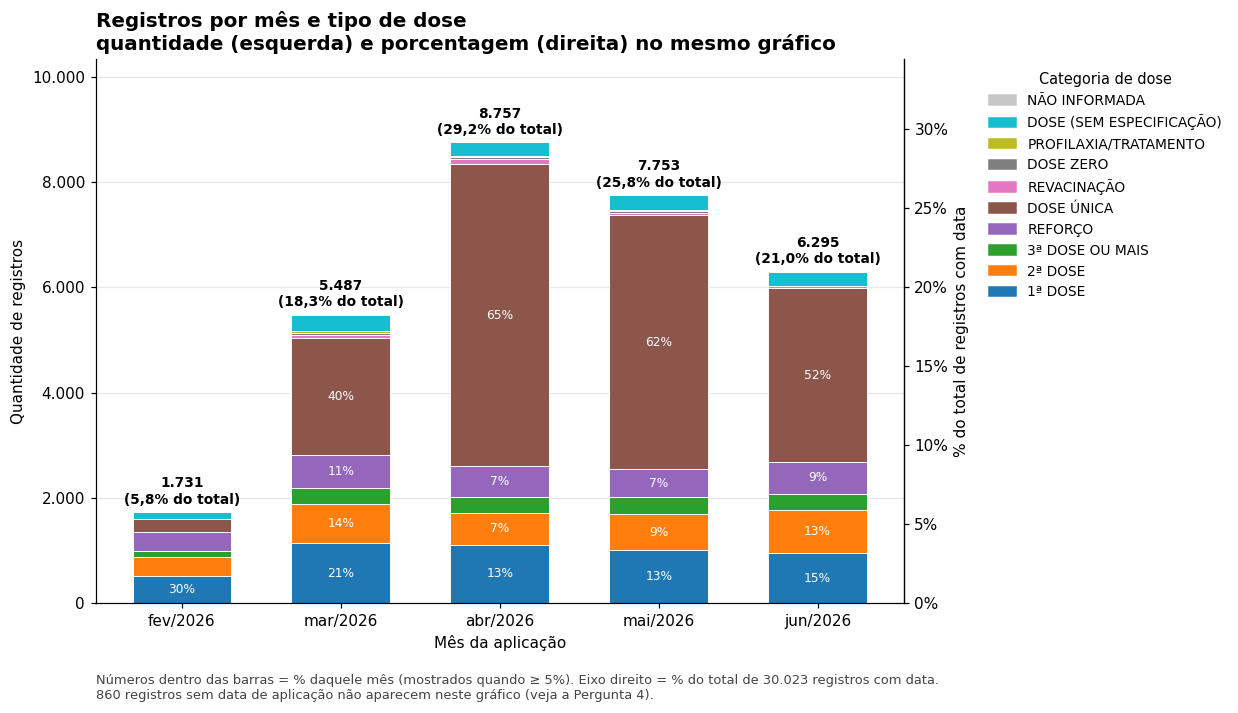

In [ ]:
dados_com_data = df.dropna(subset=["ano_mes_aplicacao"])

tab_mes_dose = (
    dados_com_data.groupby(["ano_mes_aplicacao", "dose_categoria"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)
# inclui meses sem nenhum registro entre o primeiro e o último mês (para o eixo não "pular" mês)
meses_completos = pd.period_range(tab_mes_dose.index.min(), tab_mes_dose.index.max(), freq="M").strftime("%Y-%m")
tab_mes_dose = ordenar_categorias(tab_mes_dose.reindex(meses_completos, fill_value=0))
tab_mes_dose = tab_mes_dose.loc[:, tab_mes_dose.sum() > 0]

total_mes = tab_mes_dose.sum(axis=1)
total_geral = int(total_mes.sum())
sem_data_n = int(df["ano_mes_aplicacao"].isnull().sum())

x = np.arange(len(tab_mes_dose))
fig, ax = plt.subplots(figsize=(11.5, 6.6))
base = np.zeros(len(x))
handles = []
for cat in tab_mes_dose.columns:
    vals = tab_mes_dose[cat].values.astype(float)
    cor = CATEGORY_COLORS.get(cat, "#999999")
    ax.bar(x, vals, bottom=base, color=cor, edgecolor="white", linewidth=0.6, width=0.62)
    for xi, (v, b, t) in enumerate(zip(vals, base, total_mes.values)):
        if t and v / t >= 0.05 and v >= 0.045 * total_mes.max():   # % do mês, só nos pedaços que cabem
            ax.text(xi, b + v / 2, f"{v / t * 100:.0f}%", ha="center", va="center",
                    fontsize=8, color=cor_texto_para(cor))
    base += vals
    handles.append(Patch(color=cor, label=cat))

for xi, t in enumerate(total_mes.values):
    ax.text(xi, t + total_mes.max() * 0.012, f"{fmt_int(t)}\n({fmt_pct(t / total_geral)} do total)",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_ylim(0, total_mes.max() * 1.18)
ax.set_xticks(x)
ax.set_xticklabels([rotulo_mes(m) for m in tab_mes_dose.index], fontsize=10)
eixo_milhar(ax, "y")
ax.set_ylabel("Quantidade de registros")
ax.set_xlabel("Mês da aplicação")
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)

# eixo da direita: a mesma altura das barras, lida como % do total de registros com data
ax2 = ax.secondary_yaxis("right", functions=(lambda v: v / total_geral * 100, lambda p: p * total_geral / 100))
ax2.set_ylabel("% do total de registros com data")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))

ax.set_title("Registros por mês e tipo de dose\nquantidade (esquerda) e porcentagem (direita) no mesmo gráfico",
             loc="left", fontsize=13, fontweight="bold")
ax.legend(handles=handles[::-1], title="Categoria de dose", bbox_to_anchor=(1.09, 1.0),
          loc="upper left", fontsize=9, title_fontsize=9.5, frameon=False)
ax.text(0, -0.13,
        f"Números dentro das barras = % daquele mês (mostrados quando ≥ 5%). Eixo direito = % do total de "
        f"{fmt_int(total_geral)} registros com data.\n"
        f"{fmt_int(sem_data_n)} registros sem data de aplicação não aparecem neste gráfico (veja a Pergunta 4).",
        transform=ax.transAxes, fontsize=8.5, va="top", color="#444444")
plt.tight_layout()
plt.show()

> **💡 Como ler:** cada coluna é um **mês**. A **altura** da coluna é a quantidade de registros (escala da esquerda) e, ao mesmo tempo, a porcentagem do total do período (escala da direita) — é a mesma barra lida em duas unidades. Dentro da coluna, as **cores** mostram como aquele mês se divide entre os tipos de dose e o número em cada pedaço é a **% do próprio mês**. Meses com mais registros costumam coincidir com campanhas (como a de gripe), e o **último mês pode estar incompleto**, dependendo de quando a base foi extraída.

**Leitura:** mudanças na composição de dose por vacina, bairro, estratégia ou ano refletem principalmente **o desenho de cada calendário vacinal e o mix de público atendido em cada unidade/período** (ex.: uma unidade que atendeu mais campanha de gripe terá mais "DOSE ÚNICA"; um ano com campanha de reforço de covid terá mais "REFORÇO"). Isso **não indica, por si só**, qualidade de atendimento nem comportamento dos pacientes.

### ✍️ Resposta da pergunta 2:

**Sim, a composição muda bastante**, principalmente porque cada vacina, unidade e época tem um "mix" diferente de público e de campanha:

- **Por vacina:** a gripe é ~95% dose única; difteria e tétano (adulto) tem 51% de reforço; rotavírus se divide quase meio a meio entre 1ª e 2ª dose; hepatite B e poliomielite têm bastante 3ª dose ou mais.
- **Por bairro/unidade:** a dose única vai de 46% (Mato Alto Lagoão e Morro dos Conventos) a 73% (Hercilio Luz). **Morro dos Conventos** se destaca pela 1ª dose (36% dos seus registros, contra 8% a 19% nos demais). Unidades com mais dose única são, em geral, as que tiveram mais gripe no período.
- **Por estratégia:** em *Rotina*, 44% são dose única; em *Especial*, 91%; em *Intensificação*, 60% são dose zero; em *Pós-exposição*, 44% são 3ª dose ou mais. Isso faz sentido: cada estratégia atende a um tipo de situação.
- **Por mês:** a dose única sobe de 14% em fevereiro para 40% em março e **65% em abril** (62% em maio e 52% em junho), acompanhando o início da vacinação contra a gripe (que só aparece a partir de março). Abril é também o mês com mais registros (8.757).

**Cuidados:** essas diferenças refletem o calendário de cada vacina e o tipo de atendimento, **não** qualidade do serviço nem comportamento dos pacientes. Os 860 registros sem data não entram na análise por mês, e estratégias com poucos registros (como “19” e “Pós”, rótulos cortados) variam muito com 1 registro a mais ou a menos.

## 7. Pergunta 3 — Há vacinas com muita 1ª dose e pouca 2ª dose (ou o inverso)?

Aqui olhamos, **dentro de cada vacina**, a razão entre o nº de registros de `2ª DOSE` e `1ª DOSE`.

⚠️ **Importante:** como a base é anônima e tem registros por evento (não por pessoa), essa razão **não mede abandono de esquema vacinal nem adesão**. Uma razão baixa pode significar: vacina introduzida recentemente (ainda não houve tempo de 2ª dose), calendário com intervalo longo entre doses, mudança de estratégia, ou simplesmente menor demanda no período coberto pelos dados — entre outras explicações que a base sozinha não permite distinguir.

In [ ]:
doses_1_2 = (
    df[df["dose_categoria"].isin(["1ª DOSE", "2ª DOSE"])]
    .groupby(["nome_da_vacina", "dose_categoria"])
    .size()
    .unstack(fill_value=0)
)
# só vacinas que têm pelo menos 1ª dose registrada e volume mínimo para o número fazer sentido
doses_1_2 = doses_1_2[doses_1_2.get("1ª DOSE", 0) >= 10].copy()
doses_1_2["razao_2a_sobre_1a"] = doses_1_2.get("2ª DOSE", 0) / doses_1_2["1ª DOSE"]
doses_1_2 = doses_1_2.sort_values("razao_2a_sobre_1a")

doses_1_2


dose_categoria,1ª DOSE,2ª DOSE,razao_2a_sobre_1a
nome_da_vacina,,,
Vacina pneumo 13,18,1,0.055556
Vacina pneumo 23,85,11,0.129412
Vacina hepatite A adulto,29,4,0.137931
Vacina dengue (atenuada),1017,161,0.158309
Vacina HPV quadrivalente,46,12,0.260870
Vacina hexa (DTPa/HepB/VIP/Hib),10,3,0.300000
Vacina Hib,70,21,0.300000
Vacina meningo ACWY,76,24,0.315789
Vacina influenza trivalente,485,227,0.468041


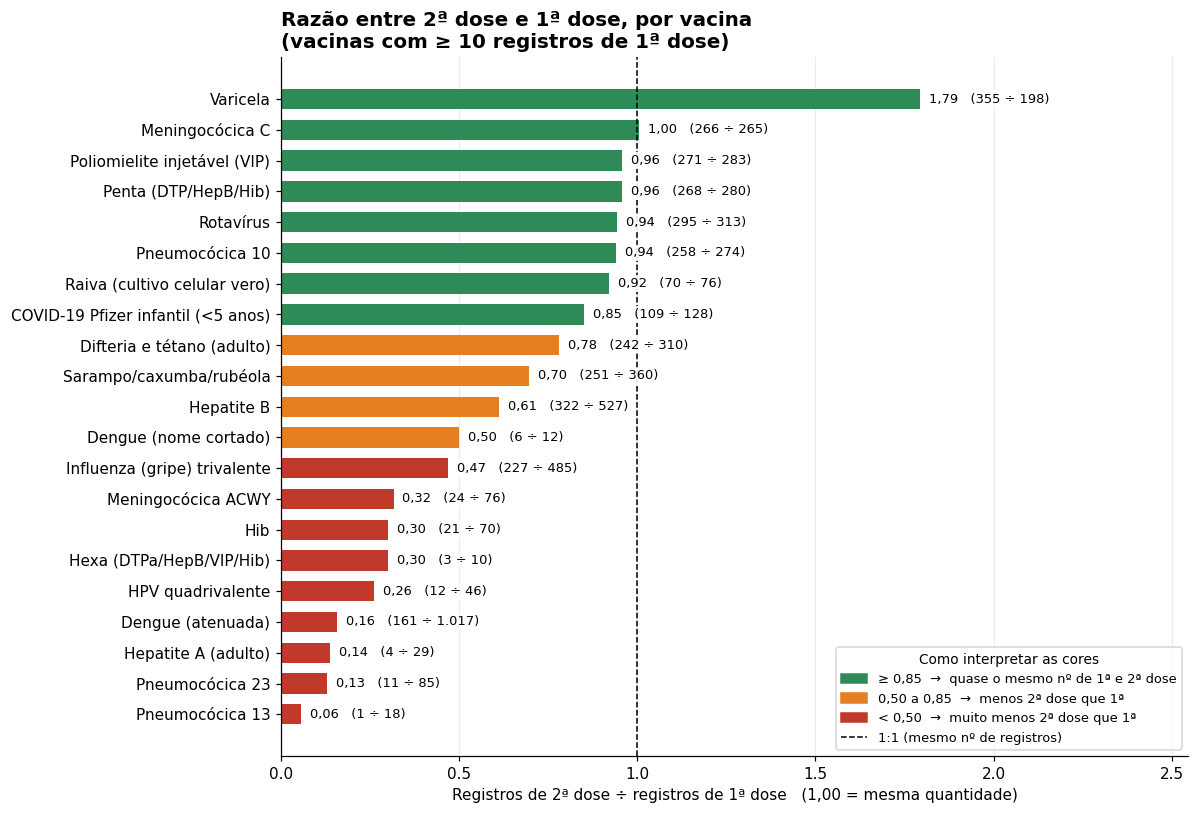

Vacinas com razão mais baixa (mais 1ª dose do que 2ª dose, em nº de registros):
nome_da_vacina
Vacina pneumo 13            0.055556
Vacina pneumo 23            0.129412
Vacina hepatite A adulto    0.137931
Vacina dengue (atenuada)    0.158309
Vacina HPV quadrivalente    0.260870
Name: razao_2a_sobre_1a, dtype: float64

Vacinas com razão mais alta (mais 2ª dose do que 1ª dose, em nº de registros):
nome_da_vacina
Vacina rotavírus                                   0.942492
Vacina penta (DTP/HepB/Hib)                        0.957143
Vacina polio injetável (inativada poliomielite)    0.957597
Vacina meningo C                                   1.003774
Vacina varicela                                    1.792929
Name: razao_2a_sobre_1a, dtype: float64


In [ ]:
razoes = doses_1_2["razao_2a_sobre_1a"]
nomes_curtos = [nome_curto_vacina(n) for n in doses_1_2.index]
cores = ["#C0392B" if r < 0.5 else ("#E67E22" if r < 0.85 else "#2E8B57") for r in razoes]

fig, ax = plt.subplots(figsize=(11, 7.5))
y = np.arange(len(razoes))
ax.barh(y, razoes.values, color=cores, height=0.66)
ax.axvline(1.0, color="black", linestyle="--", linewidth=1)
for yi, (r, n1, n2) in enumerate(zip(razoes.values, doses_1_2["1ª DOSE"], doses_1_2["2ª DOSE"])):
    ax.text(r + 0.025, yi, f"{fmt_dec(r)}   ({fmt_int(n2)} ÷ {fmt_int(n1)})", va="center", fontsize=8.5,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.2, alpha=0.9))
ax.set_yticks(y)
ax.set_yticklabels(nomes_curtos, fontsize=10)
estilo_barras(ax, razoes.max(), folga=0.42)
ax.set_xlabel("Registros de 2ª dose ÷ registros de 1ª dose   (1,00 = mesma quantidade)")
ax.set_title("Razão entre 2ª dose e 1ª dose, por vacina\n(vacinas com ≥ 10 registros de 1ª dose)",
             loc="left", fontsize=13, fontweight="bold")
ax.legend(handles=[
    Patch(color="#2E8B57", label="≥ 0,85  →  quase o mesmo nº de 1ª e 2ª dose"),
    Patch(color="#E67E22", label="0,50 a 0,85  →  menos 2ª dose que 1ª"),
    Patch(color="#C0392B", label="< 0,50  →  muito menos 2ª dose que 1ª"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=1, label="1:1 (mesmo nº de registros)"),
], title="Como interpretar as cores", loc="lower right", fontsize=8.5, title_fontsize=9, frameon=True)
plt.tight_layout()
plt.show()

print("Vacinas com razão mais baixa (mais 1ª dose do que 2ª dose, em nº de registros):")
print(doses_1_2["razao_2a_sobre_1a"].head(5))
print()
print("Vacinas com razão mais alta (mais 2ª dose do que 1ª dose, em nº de registros):")
print(doses_1_2["razao_2a_sobre_1a"].tail(5))

**Legenda dos nomes abreviados no gráfico** (nome do gráfico → nome exatamente como está na base) e os números usados no cálculo. Em `(2ª ÷ 1ª)` do gráfico, o primeiro número é a quantidade de registros de 2ª dose e o segundo, a de 1ª dose.

In [ ]:
tabela_glossario = doses_1_2.copy()
tabela_glossario.insert(0, "Nome no gráfico", [nome_curto_vacina(n) for n in tabela_glossario.index])
tabela_glossario = tabela_glossario.reset_index().rename(columns={
    "nome_da_vacina": "Nome completo na base",
    "1ª DOSE": "Registros 1ª dose", "2ª DOSE": "Registros 2ª dose", "razao_2a_sobre_1a": "Razão 2ª ÷ 1ª",
})
tabela_glossario["Razão 2ª ÷ 1ª"] = tabela_glossario["Razão 2ª ÷ 1ª"].round(2)
tabela_glossario.sort_values("Razão 2ª ÷ 1ª", ascending=False).reset_index(drop=True)

dose_categoria,Nome completo na base,Nome no gráfico,Registros 1ª dose,Registros 2ª dose,Razão 2ª ÷ 1ª
0,Vacina varicela,Varicela,198,355,1.79
1,Vacina meningo C,Meningocócica C,265,266,1.00
2,Vacina polio injetável (inativada poliomielite),Poliomielite injetável (VIP),283,271,0.96
3,Vacina penta (DTP/HepB/Hib),Penta (DTP/HepB/Hib),280,268,0.96
4,Vacina rotavírus,Rotavírus,313,295,0.94
5,Vacina pneumo 10,Pneumocócica 10,274,258,0.94
6,Vacina raiva em cultivo celular vero,Raiva (cultivo celular vero),76,70,0.92
7,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de 5 anos",COVID-19 Pfizer infantil (<5 anos),128,109,0.85
8,Vacina difteria e tétano adulto,Difteria e tétano (adulto),310,242,0.78
9,"Vacina sarampo, caxumba, rubéola",Sarampo/caxumba/rubéola,360,251,0.70


> **💡 Como ler:** cada barra compara **quantos registros de 2ª dose existem para cada registro de 1ª dose** naquela vacina. A linha tracejada (1,00) marca "mesma quantidade". **Verde** = quantidades próximas; **laranja** = a 2ª dose aparece menos; **vermelho** = aparece bem menos. Isso **não significa que as pessoas deixaram de tomar a 2ª dose** — pode ser vacina nova, intervalo longo entre as doses ou período curto de dados (veja o aviso acima).
>
> ⚠️ **Atenção a nomes repetidos:** alguns nomes de vacina foram gravados de duas formas na base (por exemplo, "Dengue" e "Dengue (atenuada)"; ver Pergunta 4, item 7). Eles foram mantidos **separados**, exatamente como estão no CSV.

**Como ler o gráfico:** barras vermelhas/laranjas têm muito mais registros de 1ª dose do que de 2ª dose; barras verdes têm quantidades próximas (ou mais 2ª dose). Isso é um **retrato do volume de registros no período coberto pela base**, não um indicador de cobertura vacinal — repetimos esse ponto porque é fácil confundir os dois.

### ✍️ Resposta da pergunta 3:

**Sim, há vacinas com muito mais 1ª dose do que 2ª dose em nº de registros** (e uma com o inverso):

- **Quase o mesmo número de 1ª e 2ª dose (razão ≥ 0,85):** meningocócica C (1,00), poliomielite injetável (0,96), penta (0,96), rotavírus (0,94), pneumocócica 10 (0,94), raiva (0,92) e COVID-19 Pfizer infantil (0,85).
- **Mais 2ª do que 1ª dose:** **varicela** (1,79: 355 registros de 2ª dose para 198 de 1ª dose).
- **Bem menos 2ª dose do que 1ª (razão < 0,50):** pneumocócica 13 (0,06), pneumocócica 23 (0,13), hepatite A adulto (0,14), dengue atenuada (0,16), HPV quadrivalente (0,26) e influenza (0,47), entre outras.

**Isso não quer dizer abandono nem baixa adesão.** A base é anônima e cobre poucos meses; razão baixa pode refletir vacina nova, intervalo longo entre as doses, público que só precisa de 1 dose em alguns casos ou 2ª dose aplicada depois do período coberto. O mesmo vale para a razão acima de 1 na varicela, cuja causa a base sozinha não permite identificar. Além disso, algumas vacinas aparecem com nomes divididos (por exemplo, "Dengue" e "Dengue (atenuada)"), o que pode distorcer a razão.

## 8. Pergunta 4 — Quais registros incompletos ou fora do padrão merecem atenção?

Aqui reunimos, de forma transparente, os pontos que a auditoria da base já sinalizou e outros que aparecem na exploração.

### 8.0 Painel-resumo: quantos registros caem em cada ponto de atenção

O gráfico abaixo junta, num só lugar, o **tamanho** de cada ponto de atenção listado nesta seção. Depois, cada ponto é detalhado com tabela (como antes) **e com gráfico**.

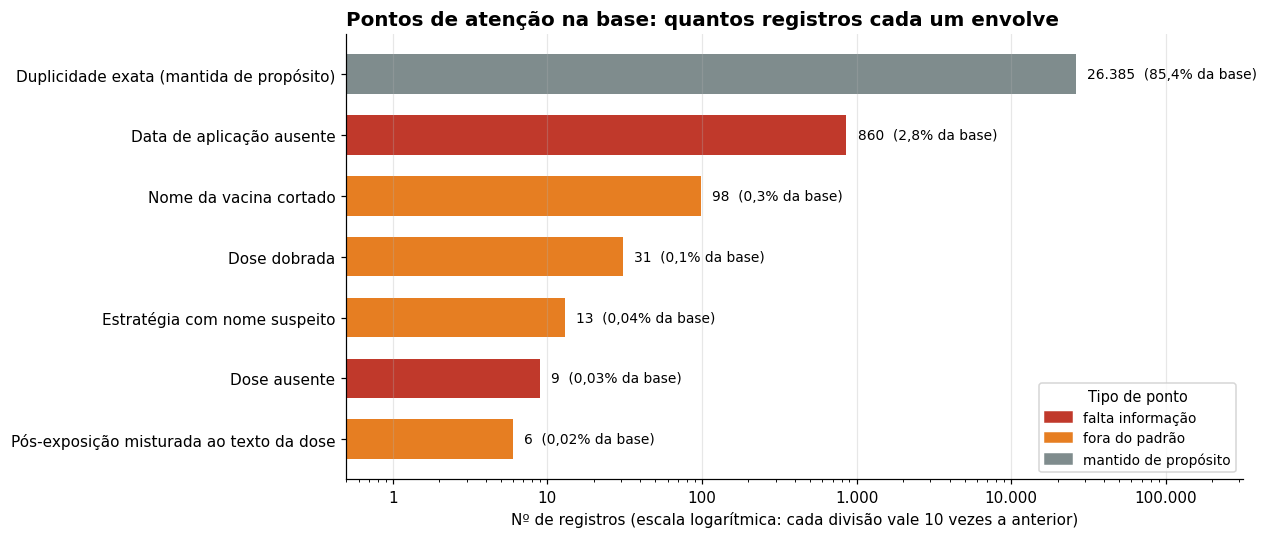

In [ ]:
colunas_originais = ["nome_do_bairro", "nome_da_vacina", "codigo_da_vacina", "estrategia",
                      "codigo_da_estrategia", "dose", "codigo_da_dose", "vacina_estrategia_e_dose",
                      "lote", "validade_do_lote", "data_da_aplicacao", "origem"]

# Colunas NOVAS de apoio (só sinalizam; nada é apagado nem corrigido no CSV)
df["estrategia_suspeita"] = df["estrategia"].isin(ESTRATEGIAS_SUSPEITAS)
# o texto completo "Nome (cód) - Estratégia (cód) - Dose (cód)" deveria começar com o nome da vacina + o código dela
df["nome_vacina_cortado"] = ~df.apply(
    lambda r: str(r["vacina_estrategia_e_dose"]).startswith(f"{r['nome_da_vacina']} ({r['codigo_da_vacina']}) - "),
    axis=1,
)
n_duplicadas = int(df.duplicated(subset=colunas_originais, keep=False).sum())

pontos = pd.DataFrame([
    ("Dose ausente",                              int(df["dose"].isnull().sum()),            "falta informação"),
    ("Data de aplicação ausente",                 int(df["ano_mes_aplicacao"].isnull().sum()), "falta informação"),
    ("Dose dobrada",                              int(df["dose_dobrada"].sum()),             "fora do padrão"),
    ("Pós-exposição misturada ao texto da dose",  int(df["dose_pos_exposicao"].sum()),       "fora do padrão"),
    ("Estratégia com nome suspeito",              int(df["estrategia_suspeita"].sum()),      "fora do padrão"),
    ("Nome da vacina cortado",                    int(df["nome_vacina_cortado"].sum()),      "fora do padrão"),
    ("Duplicidade exata (mantida de propósito)",  n_duplicadas,                              "mantido de propósito"),
], columns=["ponto", "registros", "tipo"]).sort_values("registros")

cores_tipo = {"falta informação": "#C0392B", "fora do padrão": "#E67E22", "mantido de propósito": "#7F8C8D"}

fig, ax = plt.subplots(figsize=(11.5, 5))
piso = 0.5   # escala logarítmica: as barras "nascem" em 0,5 para que os grupos pequenos apareçam
ax.barh(range(len(pontos)), pontos["registros"].values - piso, left=piso,
        color=[cores_tipo[t] for t in pontos["tipo"]], height=0.65)
for i, v in enumerate(pontos["registros"]):
    pct = v / len(df)
    ax.text(v * 1.18, i, f"{fmt_int(v)}  ({fmt_pct(pct)} da base)", va="center", fontsize=9)
ax.set_xscale("log")
ax.set_xlim(piso, pontos["registros"].max() * 12)
ax.set_yticks(range(len(pontos)))
ax.set_yticklabels(pontos["ponto"], fontsize=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: fmt_int(v)))
ax.grid(axis="y", visible=False)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("Nº de registros (escala logarítmica: cada divisão vale 10 vezes a anterior)")
ax.set_title("Pontos de atenção na base: quantos registros cada um envolve", loc="left", fontsize=13, fontweight="bold")
ax.legend(handles=[Patch(color=c, label=t) for t, c in cores_tipo.items()], title="Tipo de ponto",
          loc="lower right", fontsize=9, title_fontsize=9.5)
plt.tight_layout()
plt.show()

> **💡 Como ler:** **vermelho** = informação que está **faltando** na base; **laranja** = informação presente, mas **fora do padrão esperado** (nome cortado, texto misturado etc.); **cinza** = algo que **foi mantido de propósito** (as duplicidades — veja o item 5). A escala é **logarítmica** (cada divisão vale 10 vezes a anterior), para que os grupos pequenos também apareçam; os números ao lado de cada barra são os valores reais. Um registro pode aparecer em mais de um ponto. O objetivo não é "julgar" a base, e sim mostrar **onde olhar com mais cuidado** antes de tirar conclusões.

In [ ]:
print(f"1) Registros com campo de dose ausente: {df['dose'].isnull().sum()}")
df[df["dose"].isnull()][["nome_do_bairro", "nome_da_vacina", "estrategia", "lote", "data_da_aplicacao", "origem"]]


1) Registros com campo de dose ausente: 9


,nome_do_bairro,nome_da_vacina,estrategia,lote,data_da_aplicacao,origem
1517,Bom Pastor,"NIRSEVIMABE 1,0ml",Especial,AZ250163,01/06/2026,Carteirinha
5072,Bom Pastor,Vacina polio injetável (inativada poliomielite),Rotina,X3H851V,12/03/2026,Carteirinha
13056,Jardim Cibele,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de",Rotina,NC5436,18/05/2026,Prontuário
15266,Jardim Cibele,"Vacina sarampo, caxumba, rubéola e varicela",Rotina (1),258VVV008N,05/05/2026,Prontuário
16933,Jardim das Avenidas,Vacina polio injetável (inativada poliomielite),Rotina,X3H841V,01/02/2026,Carteirinha
22508,Polícia Rodoviária,Vacina Vírus Sincicial A e B (recombinante),Rotina,MG5689,25/03/2026,Carteirinha
25583,Sanga da Areia,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",Rotina (1),MT7306,01/03/2026,Carteirinha
26986,Sanga da Toca,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",Rotina,MT7306,01/05/2026,Carteirinha
27855,Sanga da Toca,Vacina polio injetável (inativada poliomielite),Rotina,X3H851V,01/04/2026,Carteirinha


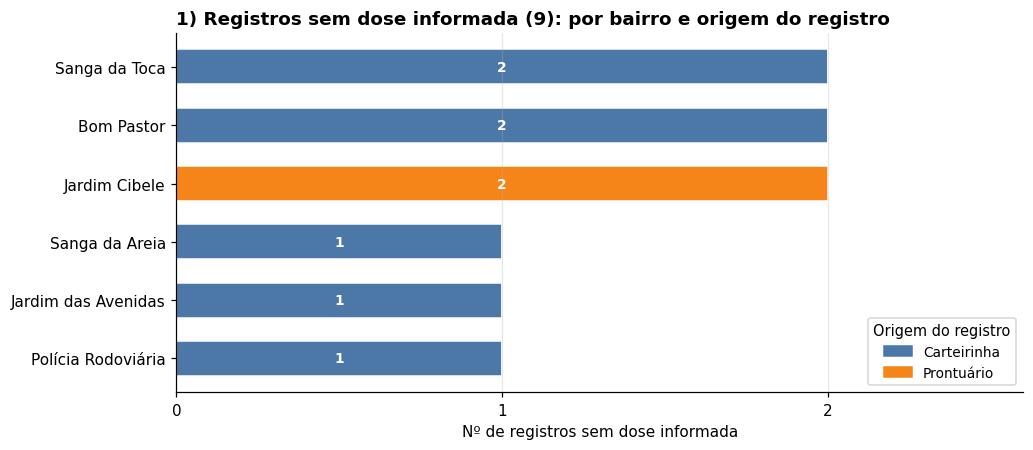

In [ ]:
ausentes = df[df["dose"].isnull()]
if len(ausentes) == 0:
    print("Nenhum registro com dose ausente.")
else:
    tab = ausentes.groupby(["nome_do_bairro", "origem"]).size().unstack(fill_value=0)
    tab = tab.loc[tab.sum(axis=1).sort_values().index]
    fig, ax = plt.subplots(figsize=(9.5, 4.2))
    esq = np.zeros(len(tab))
    handles = []
    for origem in tab.columns:
        vals = tab[origem].values.astype(float)
        cor = ORIGEM_CORES.get(origem, "#999999")
        ax.barh(tab.index, vals, left=esq, color=cor, height=0.6, edgecolor="white")
        for i, (v, l) in enumerate(zip(vals, esq)):
            if v > 0:
                ax.text(l + v / 2, i, f"{int(v)}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        esq += vals
        handles.append(Patch(color=cor, label=origem))
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.set_xlim(0, tab.sum(axis=1).max() + 0.6)
    ax.grid(axis="y", visible=False)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.set_xlabel("Nº de registros sem dose informada")
    ax.set_title(f"1) Registros sem dose informada ({len(ausentes)}): por bairro e origem do registro",
                 loc="left", fontsize=12, fontweight="bold")
    ax.legend(handles=handles, title="Origem do registro", loc="lower right", fontsize=9, title_fontsize=9.5)
    plt.tight_layout()
    plt.show()

> **💡 Como ler:** são poucos registros e estão **espalhados** por vários bairros — não é um problema concentrado em uma unidade. Nos casos com estratégia “Rotina (1)”, o texto completo da base termina em `... - Rotina (1) -`, ou seja, **a dose ficou em branco na origem** (o registro em si existe). Esses registros foram **mostrados, não descartados**.

In [ ]:
print(f"2) Registros com data de aplicação ausente ou fora dos padrões esperados: "
      f"{df['ano_mes_aplicacao'].isnull().sum()}")
df[df["ano_mes_aplicacao"].isnull()][["nome_do_bairro", "nome_da_vacina", "dose", "data_da_aplicacao", "origem"]].head(10)


2) Registros com data de aplicação ausente ou fora dos padrões esperados: 860


,nome_do_bairro,nome_da_vacina,dose,data_da_aplicacao,origem
21889,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21890,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21891,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21892,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21893,Morro dos Conventos,Vacina difteria e tétano adulto,1ª DOSE,NaN,NaN
21894,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN
21895,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN
21896,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN
21897,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN
21898,Morro dos Conventos,Vacina difteria e tétano adulto,REFORÇO,NaN,NaN


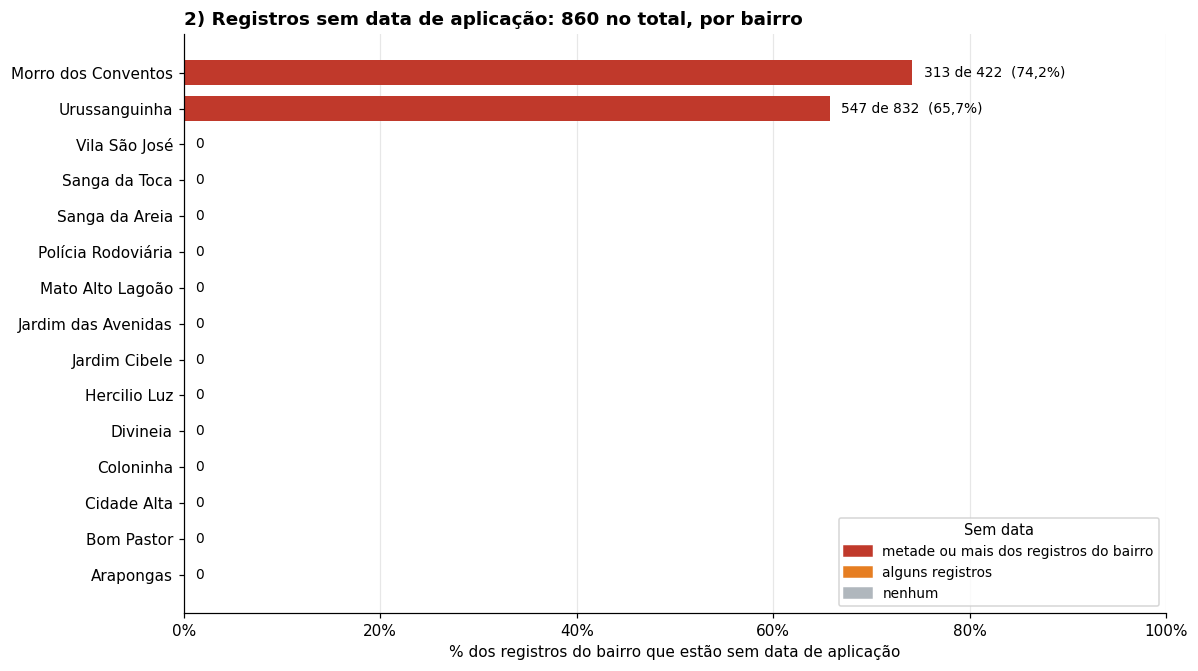

Entre os 860 registros sem data, 787 (92%) são de: Influenza (gripe) trivalente.
Em 100% deles a coluna 'origem' também está vazia.


In [ ]:
por_bairro = df.groupby("nome_do_bairro").agg(
    total=("nome_do_bairro", "size"),
    sem_data=("ano_mes_aplicacao", lambda s: int(s.isnull().sum())),
)
por_bairro["pct"] = por_bairro["sem_data"] / por_bairro["total"]
por_bairro = por_bairro.sort_values("pct")

fig, ax = plt.subplots(figsize=(11, 6.2))
cores = ["#C0392B" if p >= 0.5 else ("#E67E22" if p > 0 else "#B0B7BD") for p in por_bairro["pct"]]
ax.barh(por_bairro.index, por_bairro["pct"], color=cores, height=0.68)
for i, (p, n, t) in enumerate(zip(por_bairro["pct"], por_bairro["sem_data"], por_bairro["total"])):
    txt = "0" if n == 0 else f"{fmt_int(n)} de {fmt_int(t)}  ({fmt_pct(p)})"
    ax.text(p + 0.012, i, txt, va="center", fontsize=9)
ax.set_xlim(0, min(1.0, max(por_bairro["pct"].max(), 0.1) * 1.4))
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("% dos registros do bairro que estão sem data de aplicação")
ax.set_title(f"2) Registros sem data de aplicação: {fmt_int(por_bairro['sem_data'].sum())} no total, por bairro",
             loc="left", fontsize=12, fontweight="bold")
ax.legend(handles=[Patch(color="#C0392B", label="metade ou mais dos registros do bairro"),
                   Patch(color="#E67E22", label="alguns registros"),
                   Patch(color="#B0B7BD", label="nenhum")],
          title="Sem data", loc="lower right", fontsize=9, title_fontsize=9.5)
plt.tight_layout()
plt.show()

sem_data_df = df[df["ano_mes_aplicacao"].isnull()]
if len(sem_data_df):
    top_v = sem_data_df["nome_da_vacina"].value_counts()
    print(f"Entre os {fmt_int(len(sem_data_df))} registros sem data, {fmt_int(top_v.iloc[0])} "
          f"({fmt_pct(top_v.iloc[0] / len(sem_data_df), 0)}) são de: {nome_curto_vacina(top_v.index[0])}.")
    print(f"Em {fmt_pct(sem_data_df['origem'].isnull().mean(), 0)} deles a coluna 'origem' também está vazia.")

> **💡 Como ler:** cada barra mostra **que parte dos registros de cada bairro está sem data**. Quase todos os bairros têm 0; a falta de data **se concentra em poucas unidades** (barras vermelhas). Isso sugere um **motivo comum de preenchimento naquelas unidades** (por exemplo, um lote de fichas digitado sem data), mas a base sozinha não permite confirmar a causa — vale conferir com quem faz o registro. Esses registros ficam **de fora do gráfico por mês** (seção 6.4), o que pode fazer os bairros afetados parecerem ter menos vacinação no período do que realmente tiveram.

In [ ]:
print("3) Registros marcados como 'dose dobrada' (poucos, mas fora do padrão usual):")
print(df["dose_dobrada"].sum(), "registros")
df[df["dose_dobrada"]][["nome_da_vacina", "dose", "estrategia", "nome_do_bairro"]]


3) Registros marcados como 'dose dobrada' (poucos, mas fora do padrão usual):
31 registros


,nome_da_vacina,dose,estrategia,nome_do_bairro
2428,Vacina hepatite B,1ª DOSE DOBRADA,Especial,Bom Pastor
2535,Vacina hepatite B,4ª DOSE DOBRADA,Especial,Bom Pastor
2541,Vacina hepatite B,3ª DOSE DOBRADA,Especial,Bom Pastor
2542,Vacina hepatite B,4ª DOSE REVACINAÇÃO DOBRADA,Especial,Bom Pastor
2551,Vacina hepatite B,4ª DOSE DOBRADA,Especial,Bom Pastor
2557,Vacina hepatite B,2ª DOSE DOBRADA,Especial,Bom Pastor
2564,Vacina hepatite B,2ª DOSE DOBRADA,Especial,Bom Pastor
2565,Vacina hepatite B,2ª DOSE DOBRADA,Especial,Bom Pastor
2569,Vacina hepatite B,2ª DOSE DOBRADA,Especial,Bom Pastor
2632,Vacina hepatite B,3ª DOSE DOBRADA,Especial,Bom Pastor


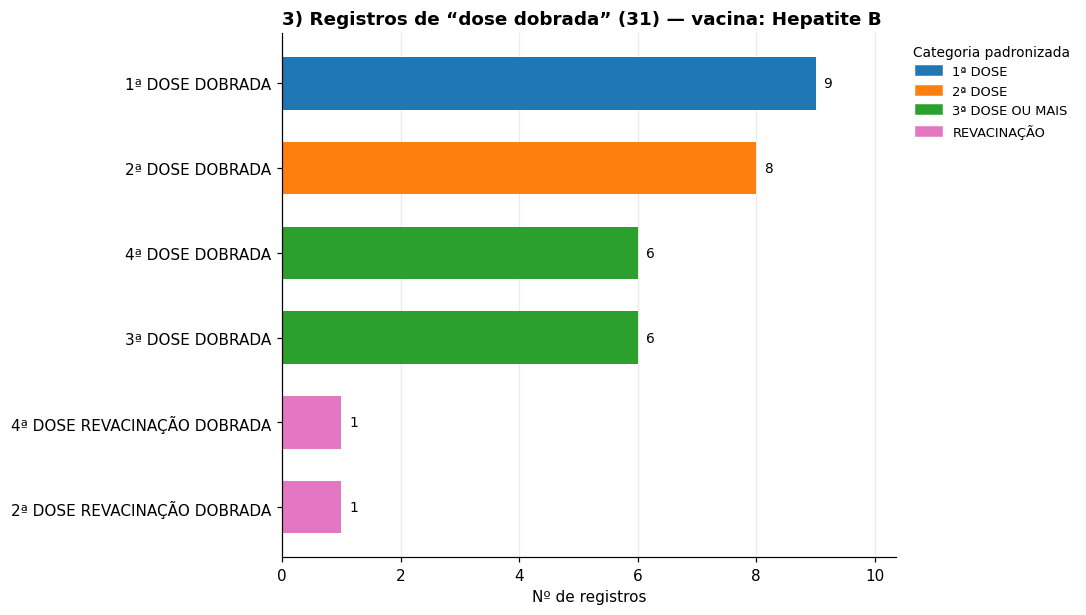

In [ ]:
def grafico_contagem_por_dose(sub, titulo, cor_fallback="#8E44AD"):
    """Barras simples: quantos registros há para cada texto de dose (cor = categoria padronizada)."""
    contagem = sub["dose"].value_counts().sort_values()
    cats = [parse_dose(t)["dose_categoria"] for t in contagem.index]
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(contagem) + 2.4))
    ax.barh(contagem.index, contagem.values, color=cores_para(cats), height=0.62)
    for i, v in enumerate(contagem.values):
        ax.text(v + contagem.max() * 0.015, i, fmt_int(v), va="center", fontsize=9)
    estilo_barras(ax, contagem.max(), folga=0.15)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.set_xlabel("Nº de registros")
    ax.set_title(titulo, loc="left", fontsize=12, fontweight="bold")
    presentes = [c for c in CATEGORY_ORDER if c in cats]
    ax.legend(handles=[Patch(color=CATEGORY_COLORS[c], label=c) for c in presentes],
              title="Categoria padronizada", bbox_to_anchor=(1.01, 1.0), loc="upper left",
              fontsize=8.5, title_fontsize=9, frameon=False)
    plt.tight_layout()
    plt.show()

dobradas = df[df["dose_dobrada"]]
if len(dobradas):
    vacinas_dobradas = ", ".join(nome_curto_vacina(v) for v in dobradas["nome_da_vacina"].unique())
    grafico_contagem_por_dose(dobradas, f"3) Registros de “dose dobrada” ({len(dobradas)}) — vacina: {vacinas_dobradas}")
else:
    print("Nenhum registro de dose dobrada.")

> **💡 Como ler:** "dose dobrada" é uma aplicação em **quantidade diferente do padrão, por indicação médica pontual**. O gráfico mostra **em qual posição do esquema** (1ª, 2ª, 3ª, 4ª dose) elas foram registradas e em qual vacina. É um volume pequeno, mas foge do padrão usual e por isso merece conferência.

In [ ]:
print("4) Registros de contexto pós-exposição misturados ao texto de dose:")
print(df["dose_pos_exposicao"].sum(), "registros")
df[df["dose_pos_exposicao"]][["nome_da_vacina", "dose", "estrategia"]]


4) Registros de contexto pós-exposição misturados ao texto de dose:
6 registros


,nome_da_vacina,dose,estrategia
28706,Vacina raiva em cultivo celular vero,exposição - 4ª DOSE,Pós
28707,Vacina raiva em cultivo celular vero,exposição - 3ª DOSE,Pós
28708,Vacina raiva em cultivo celular vero,exposição - 2ª DOSE,Pós
28709,Vacina raiva em cultivo celular vero,exposição - 4ª DOSE,Pós
28710,Vacina raiva em cultivo celular vero,exposição - 2ª DOSE,Pós
28711,Vacina raiva em cultivo celular vero,exposição - 3ª DOSE,Pós


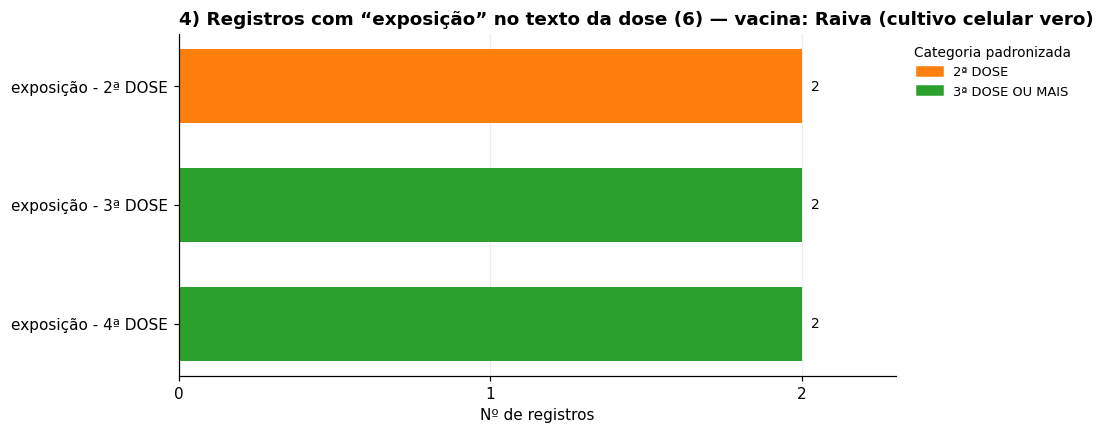

In [ ]:
pos_exp = df[df["dose_pos_exposicao"]]
if len(pos_exp):
    vacinas_pos = ", ".join(nome_curto_vacina(v) for v in pos_exp["nome_da_vacina"].unique())
    grafico_contagem_por_dose(pos_exp, f"4) Registros com “exposição” no texto da dose ({len(pos_exp)}) — vacina: {vacinas_pos}")
else:
    print("Nenhum registro com contexto de pós-exposição no texto da dose.")

> **💡 Como ler:** nesses registros o **contexto** ("pós-exposição", ou seja, vacina aplicada depois de um possível contato com o agente da doença) veio **misturado dentro do texto da dose** — por exemplo, `exposição - 3ª DOSE`. Por isso criamos a coluna `dose_pos_exposicao` para separá-los, sem mexer no texto original. São os mesmos registros cujo rótulo de estratégia aparece cortado como “Pós” (item 6).

In [ ]:
print("5) Duplicidades exatas mantidas de propósito (linhas 100% iguais em todas as colunas originais):")
colunas_originais = ["nome_do_bairro", "nome_da_vacina", "codigo_da_vacina", "estrategia",
                      "codigo_da_estrategia", "dose", "codigo_da_dose", "vacina_estrategia_e_dose",
                      "lote", "validade_do_lote", "data_da_aplicacao", "origem"]
n_duplicadas = df.duplicated(subset=colunas_originais, keep=False).sum()
print(f"{n_duplicadas:,} registros fazem parte de algum grupo de duplicidade exata "
      f"({n_duplicadas/len(df):.1%} da base).")
print("Essas linhas NÃO foram removidas: como não há identificador de paciente, "
      "duplicidades exatas podem representar procedimentos distintos e legítimos "
      "(mesmo lote/dia/estratégia para pessoas diferentes). Remover reduziria o volume real.")


5) Duplicidades exatas mantidas de propósito (linhas 100% iguais em todas as colunas originais):
26,385 registros fazem parte de algum grupo de duplicidade exata (85.4% da base).
Essas linhas NÃO foram removidas: como não há identificador de paciente, duplicidades exatas podem representar procedimentos distintos e legítimos (mesmo lote/dia/estratégia para pessoas diferentes). Remover reduziria o volume real.


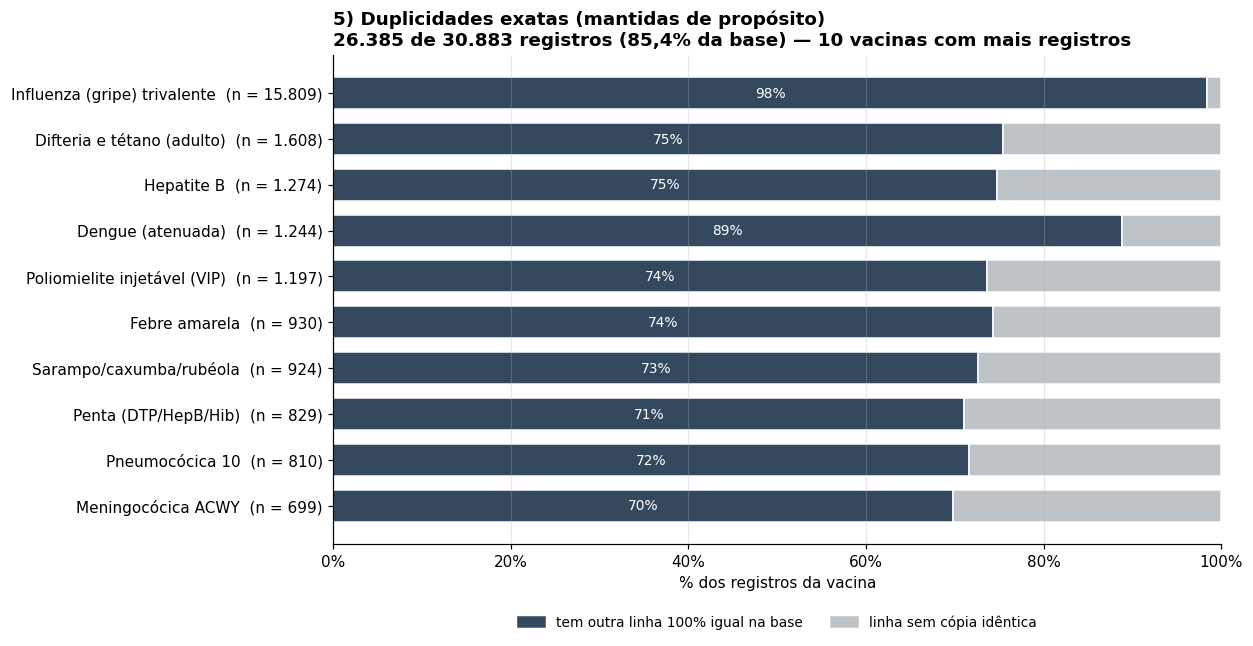

In [ ]:
dup_mask = df.duplicated(subset=colunas_originais, keep=False)
top10 = df["nome_da_vacina"].value_counts().head(10).index
tab_dup = (
    pd.crosstab(df.loc[df["nome_da_vacina"].isin(top10), "nome_da_vacina"],
                dup_mask[df["nome_da_vacina"].isin(top10)])
    .reindex(top10)
)
tab_dup.columns = ["sem cópia idêntica" if not c else "com cópia idêntica" for c in tab_dup.columns]
for col in ("sem cópia idêntica", "com cópia idêntica"):
    if col not in tab_dup:
        tab_dup[col] = 0
n_v = tab_dup.sum(axis=1)
prop_dup = tab_dup.div(n_v, axis=0)

fig, ax = plt.subplots(figsize=(11.5, 6))
y = np.arange(len(prop_dup))
ax.barh(y, prop_dup["com cópia idêntica"], color="#34495E", height=0.7, edgecolor="white")
ax.barh(y, prop_dup["sem cópia idêntica"], left=prop_dup["com cópia idêntica"], color="#BDC3C7", height=0.7, edgecolor="white")
for yi, v in enumerate(prop_dup["com cópia idêntica"]):
    if v >= 0.08:
        ax.text(v / 2, yi, f"{v * 100:.0f}%", ha="center", va="center", color="white", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels([f"{nome_curto_vacina(v)}  (n = {fmt_int(n)})" for v, n in zip(prop_dup.index, n_v)], fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("% dos registros da vacina")
ax.set_title(f"5) Duplicidades exatas (mantidas de propósito)\n"
             f"{fmt_int(n_duplicadas)} de {fmt_int(len(df))} registros ({fmt_pct(n_duplicadas / len(df))} da base) — 10 vacinas com mais registros",
             loc="left", fontsize=12, fontweight="bold")
ax.legend(handles=[Patch(color="#34495E", label="tem outra linha 100% igual na base"),
                   Patch(color="#BDC3C7", label="linha sem cópia idêntica")],
          bbox_to_anchor=(0.5, -0.12), loc="upper center", ncol=2, fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

> **💡 Como ler:** a parte **escura** da barra é a fatia de registros que têm outra linha **exatamente igual** na base (mesmo bairro, vacina, lote, data etc.). Como a base **não identifica o paciente**, várias pessoas vacinadas com o mesmo lote no mesmo dia geram linhas idênticas — por isso isso **não é, por si só, erro**, e essas linhas foram mantidas. Remover as duplicidades reduziria o volume real de aplicações.

In [ ]:
print("6) Estratégias com nomenclatura pouco clara (fora do vocabulário padrão de estratégias):")
estrategias_estranhas = df["estrategia"].value_counts()
estrategias_estranhas


6) Estratégias com nomenclatura pouco clara (fora do vocabulário padrão de estratégias):


estrategia
Rotina                                        22646
Especial                                       7791
Pós-exposição                                   239
Intensificação                                  168
Pré-exposição                                    10
Vacinação Escolar                                 6
Pós                                               6
Campanha indiscriminada                           5
19                                                5
Monitoramento das Estratégias de Vacinação        4
Rotina (1)                                        2
Bloqueio                                          1
Name: count, dtype: int64

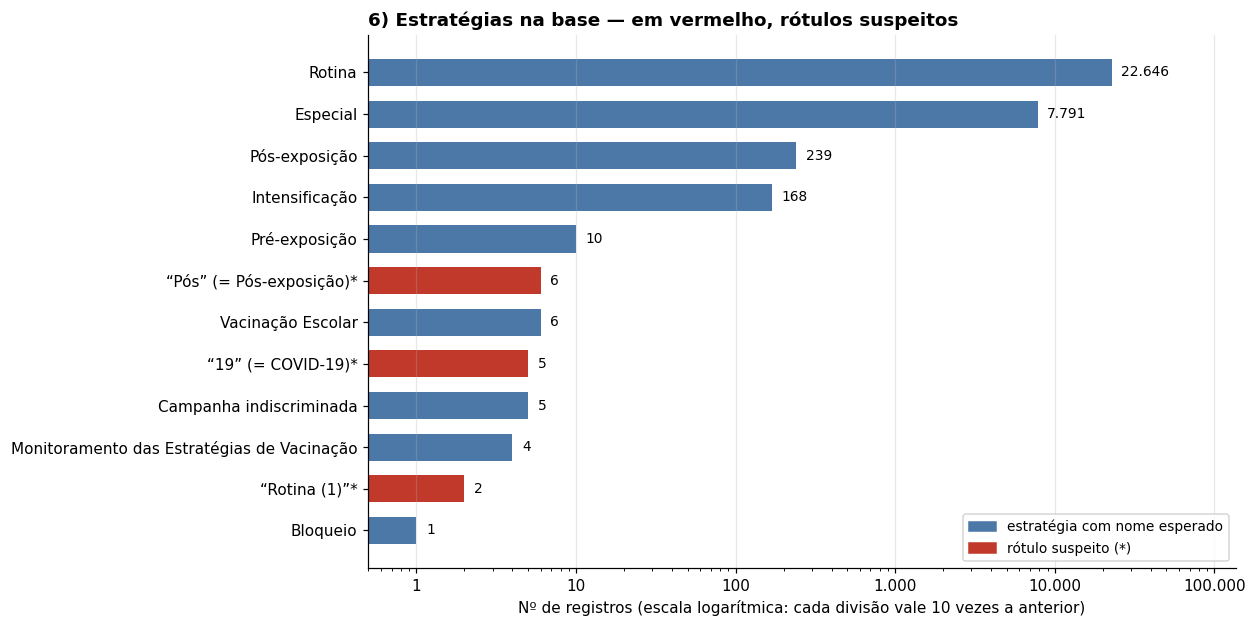

In [ ]:
cont_estr = df["estrategia"].value_counts().sort_values()
suspeita = [e in ESTRATEGIAS_SUSPEITAS for e in cont_estr.index]
rotulos_e = [ROTULO_ESTRATEGIA.get(e, e) for e in cont_estr.index]

fig, ax = plt.subplots(figsize=(11.5, 5.8))
piso = 0.5   # escala logarítmica: as barras "nascem" em 0,5 para os grupos de 1 registro aparecerem
ax.barh(range(len(cont_estr)), cont_estr.values - piso, left=piso,
        color=["#C0392B" if s else "#4C78A8" for s in suspeita], height=0.65)
for i, v in enumerate(cont_estr.values):
    ax.text(v * 1.15, i, fmt_int(v), va="center", fontsize=9)
ax.set_xscale("log")
ax.set_xlim(piso, cont_estr.max() * 6)
ax.set_yticks(range(len(cont_estr)))
ax.set_yticklabels(rotulos_e, fontsize=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: fmt_int(v)))
ax.grid(axis="y", visible=False)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("Nº de registros (escala logarítmica: cada divisão vale 10 vezes a anterior)")
ax.set_title("6) Estratégias na base — em vermelho, rótulos suspeitos", loc="left", fontsize=12, fontweight="bold")
ax.legend(handles=[Patch(color="#4C78A8", label="estratégia com nome esperado"),
                   Patch(color="#C0392B", label="rótulo suspeito (*)")],
          loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Por que consideramos esses três rótulos suspeitos?** Porque a coluna `vacina_estrategia_e_dose` guarda o texto completo original ("Vacina (cód) - Estratégia (cód) - Dose (cód)") e ele mostra qual era a estratégia de verdade:

In [ ]:
evidencia = (
    df[df["estrategia_suspeita"]]
    .groupby(["estrategia", "codigo_da_estrategia", "vacina_estrategia_e_dose"])
    .size().rename("registros").reset_index()
    .sort_values(["estrategia", "registros"], ascending=[True, False])
    .rename(columns={"estrategia": "Estratégia (como está)", "codigo_da_estrategia": "Código",
                     "vacina_estrategia_e_dose": "Texto completo original"})
)
evidencia

,Estratégia (como está),Código,Texto completo original,registros
0,19,1,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",4
1,19,1,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de 5 anos (102) - Rotina (1)...",1
2,Pós,13,Vacina raiva em cultivo celular vero (37) - Pós-exposição (13) - 2ª DOSE (2),2
3,Pós,13,Vacina raiva em cultivo celular vero (37) - Pós-exposição (13) - 3ª DOSE (3),2
4,Pós,13,Vacina raiva em cultivo celular vero (37) - Pós-exposição (13) - 4ª DOSE (4),2
5,Rotina (1),1,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) -",1
6,Rotina (1),1,"Vacina sarampo, caxumba, rubéola e varicela (56) - Rotina (1) -",1


> **💡 Como ler:** o texto original de “19” é `Vacina COVID-19-RNAm, ... - Rotina (1) - ...`: o sistema separou o texto no **hífen** de "COVID-**19**", e o “19” foi parar na coluna de estratégia. O mesmo ocorreu em “Pós-exposição” (→ “Pós”). O **código** da estratégia (coluna `Código`) confirma: 1 = Rotina, 13 = Pós-exposição. Os valores **não foram corrigidos no CSV**; apenas os gráficos passam a explicar o que cada rótulo significa.

### 8.7 Nomes de vacina cortados (item adicional)

Além dos seis pontos acima, o mesmo tipo de corte aparece em **alguns nomes de vacina**: em certos registros, a coluna `nome_da_vacina` está mais curta que o nome que consta no texto completo (`vacina_estrategia_e_dose`). Isso faz a mesma vacina aparecer em **duas linhas** nos gráficos por vacina (por exemplo, "Vacina penta" e "Vacina penta (DTP/HepB/Hib)"). Os dados **foram mantidos como estão**.

7) Registros com nome de vacina cortado: 98 (0,32% da base)


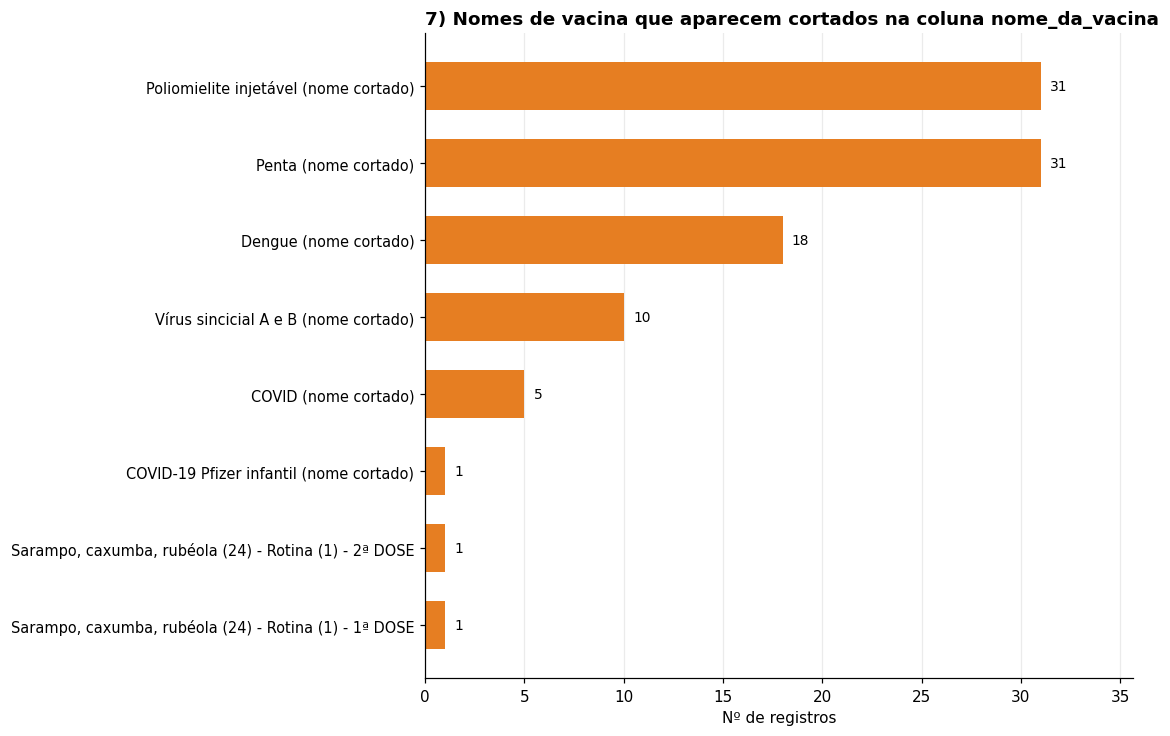

,Como está em nome_da_vacina,Texto completo original,registros
0,Vacina dengue,Vacina dengue (atenuada) (104) - Rotina (1) - 1ª DOSE (1),12
1,Vacina penta,Vacina penta (DTP/HepB/Hib) (42) - Rotina (1) - 3ª DOSE (3),12
2,Vacina Vírus Sincicial A e B,Vacina Vírus Sincicial A e B (recombinante) (108) - Rotina (1) - ÚNICA (9),10
3,Vacina penta,Vacina penta (DTP/HepB/Hib) (42) - Rotina (1) - 2ª DOSE (2),10
4,Vacina polio injetável,Vacina polio injetável (inativada poliomielite) (22) - Rotina (1) - 3ª DOSE (3),10
5,Vacina polio injetável,Vacina polio injetável (inativada poliomielite) (22) - Rotina (1) - REFORÇO (38),9
6,Vacina penta,Vacina penta (DTP/HepB/Hib) (42) - Rotina (1) - 1ª DOSE (1),9
7,Vacina polio injetável,Vacina polio injetável (inativada poliomielite) (22) - Rotina (1) - 2ª DOSE (2),8
8,Vacina dengue,Vacina dengue (atenuada) (104) - Rotina (1) - 2ª DOSE (2),6
9,Vacina COVID,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",4


In [ ]:
cortados = df[df["nome_vacina_cortado"]]
print(f"7) Registros com nome de vacina cortado: {len(cortados)} ({fmt_pct(len(cortados) / len(df), 2)} da base)")

if len(cortados):
    cont = cortados["nome_da_vacina"].value_counts().sort_values()
    rot = [nome_curto_vacina(n, limite=70) for n in cont.index]
    fig, ax = plt.subplots(figsize=(10.5, 0.55 * len(cont) + 2.4))
    ax.barh(range(len(cont)), cont.values, color="#E67E22", height=0.62)
    for i, v in enumerate(cont.values):
        ax.text(v + cont.max() * 0.015, i, fmt_int(v), va="center", fontsize=9)
    ax.set_yticks(range(len(cont)))
    ax.set_yticklabels(rot, fontsize=9.5)
    estilo_barras(ax, cont.max(), folga=0.15)
    ax.set_xlabel("Nº de registros")
    ax.set_title("7) Nomes de vacina que aparecem cortados na coluna nome_da_vacina", loc="left", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

    tabela_cortados = (
        cortados.groupby(["nome_da_vacina", "vacina_estrategia_e_dose"]).size().rename("registros").reset_index()
        .sort_values("registros", ascending=False)
        .rename(columns={"nome_da_vacina": "Como está em nome_da_vacina",
                         "vacina_estrategia_e_dose": "Texto completo original"})
        .reset_index(drop=True)
    )
    display(tabela_cortados)

> **💡 Como ler:** cada barra é um nome que aparece **incompleto** na base. Na tabela, ao lado dele está o texto completo original, que mostra o nome inteiro (por exemplo, "Vacina dengue" → "Vacina dengue **(atenuada)**"). Se você quiser somar essas linhas com a vacina "completa", isso deve ser decidido de forma consciente por quem mantém a base; neste notebook **não juntamos** os nomes automaticamente.

### ✍️ Resposta da pergunta 4:

Os registros que merecem atenção são de **três tipos**:

**1. Falta de informação**
- **Dose ausente:** 9 registros, espalhados por 6 bairros.
- **Data de aplicação ausente:** **860 registros (2,8%)**, 92% deles da vacina de gripe e concentrados em **dois bairros**: Urussanguinha (547 registros, 66% dos do bairro) e Morro dos Conventos (313, 74%). É o ponto mais relevante, porque esses registros ficam fora da análise por mês.

**2. Texto fora do padrão (provável erro de leitura/exportação)**
- **Estratégia com rótulo suspeito:** 13 registros (“19” = 5, “Pós” = 6, “Rotina (1)” = 2).
- **Nome de vacina cortado:** 98 registros (por exemplo, "Vacina penta" em vez de "Vacina penta (DTP/HepB/Hib)").
- **Dose dobrada:** 31 registros, todos da vacina de hepatite B.
- **Pós-exposição misturada ao texto da dose:** 6 registros, todos da vacina de raiva.

**3. Mantido de propósito**
- **Duplicidades exatas:** 26.385 registros (85,4% da base). Sem identificação do paciente, linhas iguais podem ser aplicações legítimas diferentes, então foram mantidas.

**Sugestão de prioridade:** conferir a falta de data nas duas unidades citadas e a origem dos cortes de texto (estratégia e nome de vacina). Em nenhum caso os dados do CSV foram alterados.

## 9. Exploração interativa

Use os filtros abaixo para explorar a composição de doses por **vacina**, **bairro**, **estratégia** e **período (ano)** — sem nunca sair do nível agregado (não há como escolher "uma pessoa").

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# No Google Colab, isso garante que os filtros (widgets) funcionem em qualquer versão
try:
    from google.colab import output as _colab_output
    _colab_output.enable_custom_widget_manager()
except Exception:
    pass

vacina_opcoes = ["(todas)"] + sorted(df["nome_da_vacina"].dropna().unique().tolist())
bairro_opcoes = ["(todos)"] + sorted(df["nome_do_bairro"].dropna().unique().tolist())
estrategia_opcoes = ["(todas)"] + sorted(df["estrategia"].dropna().unique().tolist())

# período por MÊS (a base só tem 2026, então o filtro por ano teria uma única opção)
meses_disponiveis = sorted(df["ano_mes_aplicacao"].dropna().unique().tolist())
rotulos_meses = [rotulo_mes(m) for m in meses_disponiveis] or ["(sem datas)"]
rotulo_para_mes = dict(zip(rotulos_meses, meses_disponiveis))

w_vacina = widgets.Dropdown(options=vacina_opcoes, description="Vacina:", layout=widgets.Layout(width="520px"))
w_bairro = widgets.Dropdown(options=bairro_opcoes, description="Bairro:", layout=widgets.Layout(width="520px"))
w_estrategia = widgets.Dropdown(options=estrategia_opcoes, description="Estratégia:", layout=widgets.Layout(width="520px"))
w_periodo = widgets.SelectionRangeSlider(
    options=rotulos_meses,
    index=(0, len(rotulos_meses) - 1),
    description="Meses:",
    layout=widgets.Layout(width="520px"),
)
w_sem_data = widgets.Checkbox(value=True, description="Incluir registros sem data de aplicação",
                              layout=widgets.Layout(width="520px"))
out = widgets.Output()

def atualizar(*args):
    with out:
        clear_output(wait=True)
        dados = df.copy()
        if w_vacina.value != "(todas)":
            dados = dados[dados["nome_da_vacina"] == w_vacina.value]
        if w_bairro.value != "(todos)":
            dados = dados[dados["nome_do_bairro"] == w_bairro.value]
        if w_estrategia.value != "(todas)":
            dados = dados[dados["estrategia"] == w_estrategia.value]
        if meses_disponiveis:
            m_ini, m_fim = (rotulo_para_mes[r] for r in w_periodo.value)
            dentro = dados["ano_mes_aplicacao"].between(m_ini, m_fim)
            sem_data = dados["ano_mes_aplicacao"].isna()
            dados = dados[dentro | (sem_data & w_sem_data.value)]

        print(f"Registros no filtro: {len(dados):,} de {len(df):,} "
              f"({len(dados)/len(df):.1%} da base)")

        if len(dados) == 0:
            print("Nenhum registro para essa combinação de filtros.")
            return

        contagem = dados["dose_categoria"].value_counts().sort_values()
        fig, ax = plt.subplots(figsize=(9.5, 4.8))
        ax.barh(contagem.index, contagem.values, color=cores_para(contagem.index), height=0.65)
        for i, v in enumerate(contagem.values):
            ax.text(v + contagem.max() * 0.012, i, f"{fmt_int(v)}  ({fmt_pct(v / len(dados))})", va="center", fontsize=9)
        estilo_barras(ax, contagem.max(), folga=0.28)
        eixo_milhar(ax)
        titulo_partes = []
        if w_vacina.value != "(todas)": titulo_partes.append(nome_curto_vacina(w_vacina.value))
        if w_bairro.value != "(todos)": titulo_partes.append(w_bairro.value)
        if w_estrategia.value != "(todas)": titulo_partes.append(w_estrategia.value)
        titulo = " | ".join(titulo_partes) if titulo_partes else "Base completa"
        ax.set_title(f"Composição de dose — {titulo}", loc="left", fontsize=12, fontweight="bold")
        ax.set_xlabel("Nº de registros")
        plt.tight_layout()
        plt.show()

for w in (w_vacina, w_bairro, w_estrategia, w_periodo, w_sem_data):
    w.observe(atualizar, names="value")

display(widgets.VBox([
    widgets.HTML("<b>Filtros (lembrando: sempre agregados, nunca por pessoa)</b>"),
    w_vacina, w_bairro, w_estrategia, w_periodo, w_sem_data, out
]))
atualizar()

> **💡 Como usar:** escolha uma **vacina**, um **bairro**, uma **estratégia** e o **intervalo de meses**; o gráfico atualiza sozinho e mostra quantos registros de cada tipo de dose existem naquele recorte, com a porcentagem. Deixe "(todas)"/"(todos)" para não filtrar. O filtro por **mês** substitui o antigo filtro por ano (a base só tem 2026). Se estiver no Google Colab e os filtros não aparecerem, rode a célula novamente. *Lembrete:* recortes muito pequenos (poucos registros) dão porcentagens instáveis.

## 10. Resumo para o cidadão

- **1ª dose, 2ª dose, 3ª dose, reforço:** indicam a posição do imunizante dentro de um esquema de múltiplas aplicações previsto no calendário daquela vacina.
- **Dose única:** vacinas cujo esquema padrão é aplicado uma única vez (ex.: febre amarela, na maioria dos casos).
- **Reforço / 1º e 2º reforço:** doses adicionais aplicadas depois do esquema básico, para manter a proteção ao longo do tempo.
- **Revacinação:** nova aplicação fora do esquema-padrão, geralmente por indicação específica (perda de carteira, exposição, orientação médica).
- **Dose zero:** aplicação extra antes do esquema oficial começar, usada em situações específicas (ex.: bebês em contexto de surto).
- **Dose dobrada:** quantidade diferente do padrão, aplicada por indicação médica pontual.

O que este notebook mostrou é **como esses tipos de dose se distribuem** na base — por vacina, bairro, estratégia e ano — e **onde os dados têm lacunas ou peculiaridades** (dose ausente, duplicidades mantidas de propósito, datas em formatos diferentes).

**O que ele não mostra, porque a base não permite:** se uma pessoa específica está com o esquema completo, se "abandonou" a vacinação, ou qual é a cobertura vacinal real da população — isso exigiria ligar registros a indivíduos, o que foi deliberadamente removido para proteger a privacidade dos pacientes.
